# GraphGuard: Phát Hiện Gian Lận Tài Chính (PaySim) Bằng Graph Analytics & Machine Learning

> **MỤC ĐÍCH NOTEBOOK TRÌNH CHIẾU (PRESENTATION DEMO):**
> Notebook này được thiết kế cô đọng, minh họa các nội dung chính của Phần Thực Hành (Part B — Section 4 & Section 5)** của đề bài môn Big Data:
> 1. **Live Code & Thuật toán cốt lõi:** Chạy trực tiếp trên tập mẫu kiểm chứng (~100k giao dịch tại `data/processed/sample/paysim/`), minh họa tường minh từ quy trình **ETL ánh xạ bảng giao dịch thô sang `GraphFrame(vertices, edges)` (Task 1)**, **Phân phối bậc & PageRank (Task 2)**, **Truy vấn Motif 3-Cycle & 2-Hop Relay (Task 3a)**, **Phát hiện cộng đồng LPA & Phân tích Tightly-Knit Clusters (Task 4)**, đến pipeline mở rộng **Trích xuất 35 đặc trưng Strict-Past & Huấn luyện Decision Tree Walk-Forward (Chặng 3–5)**.
> 2. **Kết quả khoa học chính thức:** Đọc và đối chiếu tự động với checkpoint đã nghiệm thu trên toàn bộ **6.362.620 giao dịch full dataset** (`results/presentation_checkpoint/paysim/`).
>
> ⚠️ **TUYÊN BỐ TRUNG THỰC (HONEST DISCLOSURE):**
> - Phần chạy live trên sample là để chứng minh tính thực thi của code từ đầu đến cuối; do tập mẫu nhỏ (~100k dòng, 153 fraud) và đồ thị cực thưa, kết quả 9 họ trên sample mang tính chất minh họa cơ chế, không dùng để xếp hạng hay rút ra kết luận khoa học.
> - Kết luận khoa học chính thức về độ cải thiện F1/AP, vai trò của từng họ đặc trưng và ngân sách điều tra nằm ở dữ liệu full-run được kiểm chứng.

---
## 0. GIỚI THIỆU 2 BỘ DỮ LIỆU & TẠI SAO CẦN KẾT HỢP PAYSIM VỚI IBM AML HI-SMALL (SECTION 4)

Dự án sử dụng thiết kế **Thực nghiệm Kép (Dual-Dataset Design)** gồm **PaySim** (bộ dữ liệu chính) và **IBM AML HI-Small** (bộ dữ liệu kiểm chứng bổ sung) để khảo sát bài toán phát hiện gian lận và rửa tiền trên đồ thị lớn:

| Tiêu chí đối chiếu | Dataset 1: PaySim (Mobile Money — Primary) | Dataset 2: IBM AML HI-Small (Multi-Bank — Complementary) |
| :--- | :--- | :--- |
| **Quy mô toàn bộ (Full Dataset)** | **6,362,620** giao dịch (cạnh `E`) / **9,073,900** tài khoản (đỉnh `V`) | **5,078,345** giao dịch (cạnh `E`) / **518,581** tài khoản (đỉnh `V`) |
| **Số giao dịch bất thường (Prevalence)** | **8,213** giao dịch gian lận (**0.129%**) | **5,177** giao dịch rửa tiền (**0.102%**) |
| **Đơn vị thời gian & Tiền tệ** | Bước giờ mô phỏng `step` (1–744 giờ, khoảng 31 ngày), 1 đơn vị tiền | `Timestamp` lịch mô phỏng (epoch seconds), **15 loại tiền tệ**, đa ngân hàng |
| **Bậc trung bình & Tự nối (Self-loops)** | Trung bình **1.40** cạnh/đỉnh (đồ thị cực thưa) / **0** self-loops | Trung bình **19.59** cạnh/đỉnh (mạng liên kết dày) / **591,212** self-loops (~11.64%) |
| **Chu trình có hướng 3 đỉnh (3-Cycles)** | **0 directed 3-cycle** (không suy ra mọi chu trình đều bằng 0) | **54 chu trình tài khoản có hướng** (**2,491** tổ hợp giao dịch vòng tròn) |
| **Cấu trúc cộng đồng LPA (Internal vs. Cross)** | **5,433,491** cụm; Top 50 cụm có **0 cạnh nội cụm** (100% cạnh liên cụm) | **314,722** cụm; có tới **852,930 cạnh nội cụm** (giao dịch nội cộng đồng) |

### 📌 Vấn đề cấu trúc của PaySim và lý do IBM AML giải quyết được:
1. **Bối cảnh PaySim:** PaySim mô phỏng giao dịch ví điện tử, có kịch bản **chiếm đoạt tài khoản (Account Takeover)**: kẻ gian đánh cắp tài khoản nạn nhân, thực hiện `TRANSFER` sang tài khoản trung gian (Mule) rồi lập tức `CASH_OUT` rút tiền mặt. Do đó:
   - Full graph có bậc trung bình thấp và không tìm thấy directed 3-cycle `A -> B -> C -> A`; chưa kết luận toàn graph là star forest hay không có chu trình dài hơn.
   - Khi chạy truy vấn chu trình 3 đỉnh cổ điển (Task 3a), PaySim trả về **0 chu trình**, buộc ta phải chuyển hướng sang khai phá mẫu hình **2-Hop Fraud Relay (`TRANSFER -> CASH_OUT`)**.
2. **Tại sao IBM AML HI-Small bổ sung góc nhìn về cấu trúc:** IBM AML được sinh từ bộ mô phỏng đa tác nhân (Multi-Agent Simulator) chuyên biệt cho **nghiệp vụ chống rửa tiền liên ngân hàng**, tích hợp sẵn **8 typology rửa tiền chuẩn** (*Cycle, Fan-In, Fan-Out, Gather-Scatter, Scatter-Gather, Stack, Bipartite, Random*). Trong đó, dòng tiền bẩn được luân chuyển qua nhiều ngân hàng rồi quay về tài khoản gốc, tạo ra **các chu trình 3 đỉnh thực sự** và **các cộng đồng có giao dịch nội bộ**, giúp minh họa và kiểm tra các thuật toán GraphFrames Motif Finding và LPA.

**Phạm vi bằng chứng:** Hai bộ dữ liệu đều là synthetic, được huấn luyện/đánh giá riêng. Các số 54 cycle / 2,491 tổ hợp IBM là audit trên subgraph đã lọc nhãn laundering, không phải kết quả phát hiện mù.


---
### CHẶNG 1 (TASK 1 — 15 ĐIỂM): XÂY DỰNG ĐỒ THỊ (`GRAPHFRAME`) TỪ DỮ LIỆU THÔ & KIỂM TRA TOÀN VẸN
#### 1.1 Kỹ Thuật ETL: Ánh Xạ Bảng Giao Dịch Thô Sang `Vertices DF` & `Edges DF`
*Lời trình bày:* Trước khi nạp toàn bộ đồ thị mẫu, ta minh họa trực tiếp quy trình biến đổi từ **Raw Schema gốc của PaySim** (`nameOrig`, `nameDest`, `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`, `step`, `type`, `amount`, `isFraud`) sang `GraphFrame(vertices, edges)`:
1. **Trích xuất tập đỉnh (`Vertices DF`):** Hợp nhất mọi tài khoản từ cả `nameOrig` và `nameDest`, phân loại tiền tố `C` (`Customer`) / `M` (`Merchant`), và dùng cửa sổ `Window.partitionBy("id").orderBy(F.col("step").desc())` để lấy số dư cuối cùng (`balance`) tại thời điểm `max(step)`.
2. **Xây dựng tập cạnh (`Edges DF`):** Ánh xạ `nameOrig -> src`, `nameDest -> dst` kèm các thuộc tính giao dịch.


In [1]:
# Cell C1a: Preflight, Spark Initialization & Raw-to-GraphFrame ETL Demonstration (Task 1)
import os
import sys
import time
import tempfile
import atexit
import json
import hashlib
import pandas as pd
import platform
from pathlib import Path
from dataclasses import dataclass, field
from contextlib import contextmanager
from IPython.display import Image, display

# 1. Tìm gốc repository tự động
current_dir = Path(os.getcwd()).resolve()
repo_root = current_dir
while not (repo_root / "src" / "common" / "spark_session.py").exists():
    if repo_root.parent == repo_root:
        raise FileNotFoundError("Không tìm thấy gốc repository chứa src/common/spark_session.py")
    repo_root = repo_root.parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

print(f"[PREFLIGHT] Gốc repository: {repo_root}")

if os.name != "nt" or sys.version_info[:2] != (3, 12):
    raise RuntimeError("Chạy bằng Windows Python 3.12 trong .venv của repository.")
if not os.path.samefile(sys.executable, repo_root / ".venv/Scripts/python.exe"):
    raise RuntimeError("Chọn kernel GraphGuard (.venv Windows).")

# 2. Kiểm tra môi trường (Python, Java, các thư viện phụ thuộc)
print(f"[PREFLIGHT] Python interpreter: {sys.version.split()[0]} ({sys.executable})")
java_home = os.environ.get("JAVA_HOME", "")
print(f"[PREFLIGHT] JAVA_HOME: {java_home if java_home else 'Chưa set JAVA_HOME (sử dụng PATH hệ thống)'}")

for pkg_name in ["pyspark", "graphframes", "pandas", "matplotlib", "IPython"]:
    try:
        __import__(pkg_name)
        print(f"  • Thư viện {pkg_name:<12}: [OK]")
    except ImportError as e:
        raise ImportError(f"Thiếu thư viện bắt buộc '{pkg_name}'. Vui lòng kích hoạt .venv và cài đặt requirements.txt!") from e

# 3. Kiểm tra tài nguyên và đường dẫn đầu vào
sample_dir = repo_root / "data" / "processed" / "sample" / "paysim"
checkpoint_dir = repo_root / "results" / "presentation_checkpoint" / "paysim"

assert (sample_dir / "vertices.parquet").exists(), f"Thiếu file {sample_dir / 'vertices.parquet'}"
assert (sample_dir / "edges.parquet").exists(), f"Thiếu file {sample_dir / 'edges.parquet'}"
assert checkpoint_dir.exists(), f"Thiếu thư mục checkpoint: {checkpoint_dir}"

# Xác thực các artifacts full được dùng; không thay đổi chúng.
checkpoint_root = checkpoint_dir.parent
manifest = json.loads((checkpoint_root / "MANIFEST.json").read_text(encoding="utf-8"))
def verify_checkpoint(relative):
    entry = manifest[relative]
    data = (checkpoint_root / relative).read_bytes()
    actual = hashlib.sha256(data).hexdigest()
    mode = "exact bytes"
    if actual != entry["sha256"]:
        assert Path(relative).suffix.lower() in {".csv", ".json", ".md"}, relative
        lf = data.replace(b"\r\n", b"\n")
        candidates = {"checkout LF; source CRLF": lf.replace(b"\n", b"\r\n"),
                      "checkout CRLF; source LF": lf}
        matches = [name for name, raw in candidates.items()
                   if hashlib.sha256(raw).hexdigest() == entry["sha256"] and len(raw) == entry["bytes"]]
        assert matches, f"Checkpoint content changed: {relative}"
        mode = matches[0]
    else:
        assert len(data) == entry["bytes"], relative
    return {"actual_sha256": actual, "source_sha256": entry["sha256"], "verification": mode}

verified_checkpoints = {relative: verify_checkpoint(relative)
                        for relative in manifest if relative.startswith(("paysim/", "common/"))}
from collections import Counter
print("[CHECKPOINT VERIFICATION]", dict(Counter(v["verification"] for v in verified_checkpoints.values())))
input_sha256 = {
    path.relative_to(repo_root).as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
    for path in sorted(sample_dir.rglob("*.parquet")) if path.is_file()
}
assert input_sha256, "Không có sample Parquet đầu vào"
print("[INPUT SHA256]", json.dumps(input_sha256, ensure_ascii=False))

# 4. Tạo thư mục tạm an toàn
temp_scratch_obj = tempfile.TemporaryDirectory(prefix="gg_paysim_demo_")
temp_scratch = Path(temp_scratch_obj.name)
atexit.register(temp_scratch_obj.cleanup)
print(f"[TEMP] Scratch directory độc lập: {temp_scratch}")

@contextmanager
def timed(label: str):
    t0 = time.perf_counter()
    yield
    print(f"  [{label}] Hoàn thành trong {time.perf_counter() - t0:.2f}s")

# 5. Khởi tạo SparkSession có Hardware Guard
from pyspark.sql import functions as F, Window
from graphframes import GraphFrame
from src.common.spark_session import get_graph_session
from src.common.graph_utils import load_graph, check_integrity
from src.paysim.etl_mapping import build_vertices_df, build_edges_df

with timed("Khởi tạo SparkSession"):
    spark = get_graph_session(
        app_name="GraphGuard-PaySim-Presentation",
        driver_memory="5g",
        shuffle_partitions=16,
        checkpoint_dir=str(temp_scratch / "spark_checkpoints"),
        extra_configs={
            "spark.hadoop.parquet.block.size": str(32 * 1024 * 1024),
            "spark.sql.parquet.columnarReaderBatchSize": "1024",
            "spark.sql.inMemoryColumnarStorage.batchSize": "1000",
            "spark.ui.showConsoleProgress": "false",
        }
    )

assert spark.sparkContext._jvm.java.lang.System.getProperty("java.version").split(".")[0] == "17"
from src.common import hardware_guard
print("[RUNTIME]", platform.platform(), "Spark", spark.version, "Java", os.environ["JAVA_HOME"])
print("[RESOURCE]", json.dumps(hardware_guard._GUARD.snapshot()))

# Hàm materialize dùng Parquet để cắt lineage; không dùng localCheckpoint.
def stage(frame, name):
    path = temp_scratch / (name + ".parquet")
    frame.write.mode("overwrite").parquet(str(path))
    return spark.read.parquet(str(path))

def assert_same_rows(actual, expected, columns, label):
    # Materialize both inputs so Spark 3.5 cannot prune deduplicated/constant
    # columns incorrectly while planning EXCEPT ALL on the ETL lineage.
    key = label.replace(" ", "_")
    left = stage(actual.select(*columns), f"etl_compare_{key}_inline")
    right = stage(expected.select(*columns), f"etl_compare_{key}_reference")
    assert left.count() == right.count(), f"{label}: row count mismatch"
    assert not left.exceptAll(right).limit(1).count(), f"{label}: unexpected inline row"
    assert not right.exceptAll(left).limit(1).count(), f"{label}: missing inline row"
    print(f"[ETL VERIFIED] {label}: counts + values + multiplicity MATCH")

print("[ETL SCOPE] Fixture raw-schema tái dựng từ tối đa 1,000 giao dịch sample; không phải đọc lại CSV raw gốc.")

# 6. MINH HỌA KỸ THUẬT ETL (TASK 1): Biến đổi 1,000 dòng giao dịch ở Raw Schema gốc -> GraphFrame(vertices, edges)
with timed("Minh họa ETL từ 1,000 dòng Raw Schema sang GraphFrame"):
    raw_sample_edges = spark.read.parquet(str(sample_dir / "edges.parquet")).limit(1000)
    raw_sample_verts = spark.read.parquet(str(sample_dir / "vertices.parquet"))
    
    # Tái lập bảng giao dịch thô đúng định dạng CSV gốc của PaySim (nameOrig, nameDest, oldbalanceOrg, newbalanceOrig...)
    raw_paysim_df = (
        raw_sample_edges
        .join(raw_sample_verts.select(F.col("id").alias("src"), F.col("balance").alias("newbalanceOrig")), "src", "left")
        .join(raw_sample_verts.select(F.col("id").alias("dst"), F.col("balance").alias("newbalanceDest")), "dst", "left")
        .select(
            F.col("step"), F.col("type"), F.col("amount"),
            F.col("src").alias("nameOrig"),
            (F.col("newbalanceOrig") + F.col("amount")).alias("oldbalanceOrg"),
            F.col("newbalanceOrig"),
            F.col("dst").alias("nameDest"),
            F.lit(0.0).alias("oldbalanceDest"),
            F.col("newbalanceDest"),
            F.col("isFraud"),
        )
    )
    
    # [A] Xây dựng Vertices DF: Hợp nhất nameOrig & nameDest, lấy balance tại max(step) và gán nhãn Customer/Merchant
    orig_accounts = raw_paysim_df.select(F.col("nameOrig").alias("id"), F.col("newbalanceOrig").alias("balance"), F.col("step"))
    dest_accounts = raw_paysim_df.select(F.col("nameDest").alias("id"), F.col("newbalanceDest").alias("balance"), F.col("step"))
    all_endpoints = orig_accounts.unionByName(dest_accounts)
    
    latest_win = Window.partitionBy("id").orderBy(F.col("step").desc())
    v_raw_demo = (
        all_endpoints
        .withColumn("rn", F.row_number().over(latest_win))
        .where(F.col("rn") == 1)
        .drop("rn", "step")
        .withColumn("account_type", F.when(F.col("id").startswith("C"), F.lit("Customer"))
            .when(F.col("id").startswith("M"), F.lit("Merchant")).otherwise(F.lit("Unknown")))
        .select("id", "account_type", "balance")
    )
    
    # [B] Xây dựng Edges DF: Ánh xạ nameOrig -> src, nameDest -> dst
    e_raw_demo = raw_paysim_df.select(
        F.col("nameOrig").alias("src"),
        F.col("nameDest").alias("dst"),
        F.col("amount").cast("double").alias("amount"),
        F.col("step").cast("int").alias("step"),
        F.col("type"),
        F.col("isFraud").cast("short").alias("isFraud"),
    )
    
    # [C] Khởi tạo GraphFrame & đối chiếu với hàm chuẩn trong src.paysim.etl_mapping
    g_raw_demo = GraphFrame(v_raw_demo, e_raw_demo)
    ref_v_demo = build_vertices_df(raw_paysim_df)
    ref_e_demo = build_edges_df(raw_paysim_df)
    assert_same_rows(v_raw_demo, ref_v_demo, v_raw_demo.columns, "PaySim vertices")
    assert_same_rows(e_raw_demo, ref_e_demo, e_raw_demo.columns, "PaySim edges")

print("\n[TASK 1 — DEMO ETL TRÊN 1,000 DÒNG GIAO DỊCH THÔ]:")
print(f"  • Input Raw DataFrame : {raw_paysim_df.count():,} giao dịch -> Output GraphFrame: {g_raw_demo.vertices.count():,} đỉnh, {g_raw_demo.edges.count():,} cạnh")
print("  • 5 dòng mẫu Vertices DF (id, account_type, balance tại max(step)):")
g_raw_demo.vertices.show(5, truncate=False)
print("  • 5 dòng mẫu Edges DF (src, dst, amount, step, type, isFraud):")
g_raw_demo.edges.show(5, truncate=False)


[PREFLIGHT] Gốc repository: D:\Desktop_informations\SGK năm 4\SGK kì 1 năm 4\BigData - Phong\Project_graphX\graphguard-amls-detection
[PREFLIGHT] Python interpreter: 3.12.10 (D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\.venv\Scripts\python.exe)
[PREFLIGHT] JAVA_HOME: C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot\
  • Thư viện pyspark     : [OK]
  • Thư viện graphframes : [OK]
  • Thư viện pandas      : [OK]
  • Thư viện matplotlib  : [OK]
  • Thư viện IPython     : [OK]
[CHECKPOINT VERIFICATION] {'checkout LF; source CRLF': 32, 'exact bytes': 44}
[INPUT SHA256] {"data/processed/sample/paysim/edges.parquet/part-00000-011827eb-c383-4e59-8de7-09e677db4d9f-c000.snappy.parquet": "94b1a6c91baa0f8c37772db7feb97e173c564371eb86a7ca4ce64a9f2683d290", "data/processed/sample/paysim/vertices.parquet/part-00000-02021864-2787-462e-9655-8ba37edbeea2-c000.snappy.parquet": "dfa76505fc341f0e908c3997bf24d54af964ba067fd54a7d5f8f6ac1a

[TEMP] Scratch directory độc lập: C:\Users\ADMIN\AppData\Local\Temp\gg_paysim_demo_i3rxw3fx
[RESOURCE] One workload; CPU capacity 100%; 20 CPUs available / 20 Spark tasks; job commit cap 8.0 GiB; RAM reserve 7.9 GiB


[RESOURCE] Effective Spark local[20], heap 5120m; spill before increasing RAM


[*] Checkpoint directory: C:\Users\ADMIN\AppData\Local\Temp\gg_paysim_demo_i3rxw3fx\spark_checkpoints
  [Khởi tạo SparkSession] Hoàn thành trong 4.25s
[RUNTIME] Windows-11-10.0.26300-SP0 Spark 3.5.1 Java C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
[RESOURCE] {"cpu_hard_cap_percent": 100, "max_logical_cpus": 20, "spark_task_slots": 20, "job_cpu_seconds": 9.75, "job_wall_seconds": 4.219, "average_job_cpu_percent": 11.55, "maximum_job_cpu_percent": 9.14, "job_commit_cap_gib": 8.0, "peak_job_commit_gib": 1.39, "minimum_available_ram_gib": 20.38, "maximum_host_cpu_percent": 25.1, "thermal_sensor": "CPU temperature unavailable; not a thermal/power hardware guarantee"}
[ETL SCOPE] Fixture raw-schema tái dựng từ tối đa 1,000 giao dịch sample; không phải đọc lại CSV raw gốc.


[ETL VERIFIED] PaySim vertices: counts + values + multiplicity MATCH


[ETL VERIFIED] PaySim edges: counts + values + multiplicity MATCH
  [Minh họa ETL từ 1,000 dòng Raw Schema sang GraphFrame] Hoàn thành trong 10.48s

[TASK 1 — DEMO ETL TRÊN 1,000 DÒNG GIAO DỊCH THÔ]:


  • Input Raw DataFrame : 1,000 giao dịch -> Output GraphFrame: 1,996 đỉnh, 1,000 cạnh
  • 5 dòng mẫu Vertices DF (id, account_type, balance tại max(step)):


+-----------+------------+----------+
|id         |account_type|balance   |
+-----------+------------+----------+
|C100045266 |Customer    |2349966.97|
|C1000610515|Customer    |9429341.45|
|C1000821851|Customer    |452981.2  |
|C1001210058|Customer    |0.0       |
|C1003130212|Customer    |8387275.36|
+-----------+------------+----------+
only showing top 5 rows

  • 5 dòng mẫu Edges DF (src, dst, amount, step, type, isFraud):


+-----------+-----------+---------+----+--------+-------+
|src        |dst        |amount   |step|type    |isFraud|
+-----------+-----------+---------+----+--------+-------+
|C1938534300|C1825992554|56307.27 |7   |CASH_IN |0      |
|C354376449 |M53521551  |13723.72 |17  |PAYMENT |0      |
|C1565256254|C871995390 |229715.83|15  |CASH_OUT|0      |
|C1084725283|M1809278304|2253.66  |17  |PAYMENT |0      |
|C903945186 |C1696758742|216701.76|9   |CASH_OUT|0      |
+-----------+-----------+---------+----+--------+-------+
only showing top 5 rows



#### 1.2 Nạp Đồ Thị `sample_100k`, Kiểm Tra Toàn Vẹn & Đối Chiếu Với Full Dataset
*Lời trình bày:* Nạp đồ thị `sample_100k` phục vụ chuỗi thực nghiệm live, kiểm tra tự động các điều kiện toàn vẹn cấu trúc (**0 null IDs, 0 dangling edges, 0 self-loops**) và đặt cạnh bảng thống kê nghiệm thu trên toàn bộ **6.36 triệu giao dịch Full Dataset**.


In [2]:
# Cell C1b: Load Sample GraphFrame, Integrity Check & Full-Dataset Reconciliation
graph = load_graph(spark, str(sample_dir))
v_count = graph.vertices.count()
e_count = graph.edges.count()

print(f"[GRAPH LOADED] GraphFrame PaySim Sample:")
print(f"  • Số lượng đỉnh (|V| - tài khoản): {v_count:,}")
print(f"  • Số lượng cạnh (|E| - giao dịch): {e_count:,}")
print(f"  • Phân bố loại tài khoản (Customer vs. Merchant) trên Sample:")
graph.vertices.groupBy("account_type").count().show()

assert e_count > 0 and v_count > 0
integrity = check_integrity(graph)
assert all(integrity[key] == 0 for key in ("null_vertices", "null_edges", "dangling_edges"))
assert graph.vertices.select("id").distinct().count() == v_count

# Đối chiếu trực tiếp với bảng tổng quan Full Dataset từ checkpoint nghiệm thu
overview_df = pd.read_csv(checkpoint_root / "common" / "tables" / "dataset_overview.csv")
print("\n[BẢNG ĐỐI CHIẾU QUY MÔ & CẤU TRÚC TOÀN BỘ 2 BỘ DỮ LIỆU (FULL RUN CHECKPOINT)]:")
print(overview_df[["dataset", "transactions", "accounts", "positives", "prevalence", "self_loops", "mean_total_degree", "communities", "internal_edges", "cross_edges"]].to_string(index=False))
print("\n[SAMPLE] Dữ liệu sample_100k chạy live; các bảng/biểu đồ Full Run được đối chiếu trực tiếp từ checkpoint.")


[GRAPH LOADED] GraphFrame PaySim Sample:
  • Số lượng đỉnh (|V| - tài khoản): 194,195
  • Số lượng cạnh (|E| - giao dịch): 100,729
  • Phân bố loại tài khoản (Customer vs. Merchant) trên Sample:
+------------+------+
|account_type| count|
+------------+------+
|    Customer|160262|
|    Merchant| 33933|
+------------+------+



GRAPHFRAME INTEGRITY REPORT
  Vertices (|V|):       194,195
  Edges (|E|):          100,729
  Null Vertices:        0  [PASS]
  Null Edges (src/dst): 0  [PASS]
  Dangling Edges:       0  (src-side: 0, dst-side: 0)  [PASS]
  Self-loops (src==dst):0



[BẢNG ĐỐI CHIẾU QUY MÔ & CẤU TRÚC TOÀN BỘ 2 BỘ DỮ LIỆU (FULL RUN CHECKPOINT)]:
dataset  transactions  accounts  positives  prevalence  self_loops  mean_total_degree  communities  internal_edges  cross_edges
ibm_aml       5078345    518581       5177    0.001019      591212          19.585542       314722          852930      4225415
 paysim       6362620   9073900       8213    0.001291           0           1.402400      5433491               0      6362620

[SAMPLE] Dữ liệu sample_100k chạy live; các bảng/biểu đồ Full Run được đối chiếu trực tiếp từ checkpoint.


---
### CHẶNG 2 (TASKS 2, 3, 4 — 50 ĐIỂM): ĐỘ ĐO CẤU TRÚC, PAGERANK, CỘNG ĐỒNG LPA & MOTIF FINDING
#### 2.1 Phân Phối Bậc (`inDegrees`, `outDegrees`, `degrees`), Bất Biến Euler & Phân Phối Đuôi Dài (Task 2a)
*Lời trình bày:* Mỗi giao dịch đóng góp đúng 1 vào `outDegree` của người gửi và 1 vào `inDegree` của người nhận; do đó tổng bậc toàn đồ thị luôn bằng đúng 2 lần số cạnh (`Σ degree = 2 * |E|`). Đồng thời, ta vẽ phân phối bậc trên thang log-log để quan sát phân phối bậc lệch, có đuôi dài (đa số tài khoản là nút lá chỉ giao dịch 1 lần, một số ít tài khoản đóng vai trò Hub giao dịch lớn).

Biểu đồ log–log mô tả dữ liệu quan sát; chưa có fit/kiểm định để khẳng định power-law.


  [Tính toán Degree Metrics] Hoàn thành trong 0.91s
[DEGREE INVARIANT CHECK TRÊN SAMPLE]
  • Tổng bậc Σ degree: 201,458
  • 2 * Số cạnh (2|E|): 201,458
  => [PASS] Đồ thị bảo toàn toàn vẹn liên kết.

[TOP 5 TÀI KHOẢN CÓ TỔNG BẬC CAO NHẤT TRÊN SAMPLE]:


+-----------+--------+---------+------+
|         id|inDegree|outDegree|degree|
+-----------+--------+---------+------+
|C1675375648|       6|        0|     6|
| C746062580|       6|        0|     6|
| C234827271|       5|        0|     5|
|C2073764942|       5|        0|     5|
|C1867332127|       5|        0|     5|
+-----------+--------+---------+------+
only showing top 5 rows

[PHÂN PHỐI BẬC TRÊN FULL DATASET PAYSIM (9,073,900 TÀI KHOẢN — TOP 5 MỨC BẬC ĐẦU & ĐUÔI HUB)]:
 degree  account_count
      1        8604623
      2          86428
      3          57345
      4          45157
      5          36862
    101              2
    102              1
    105              1
    109              1
    113              1

[Biểu đồ Phân phối Bậc Full PaySim (Log-Log Scale)]:


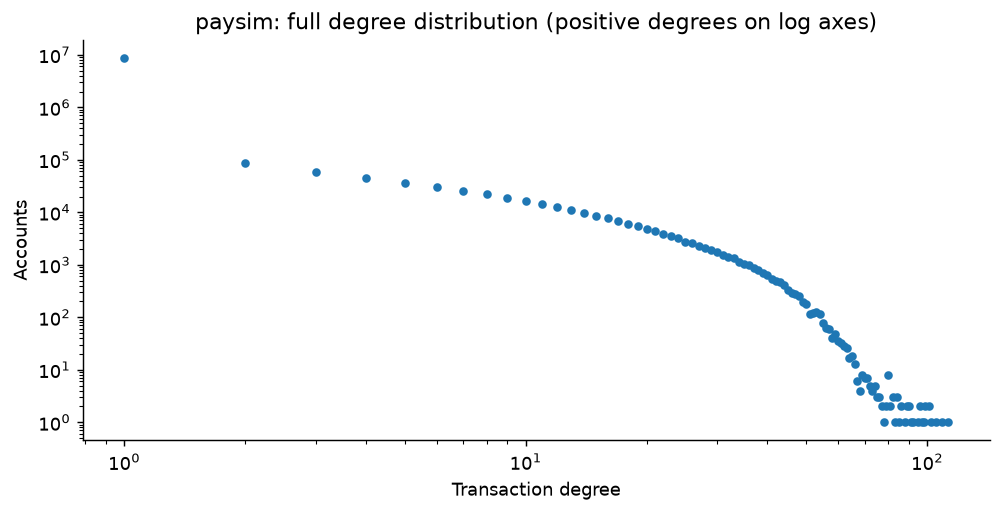


[So sánh Phân phối Bậc Power-Law: PaySim vs. IBM AML]:


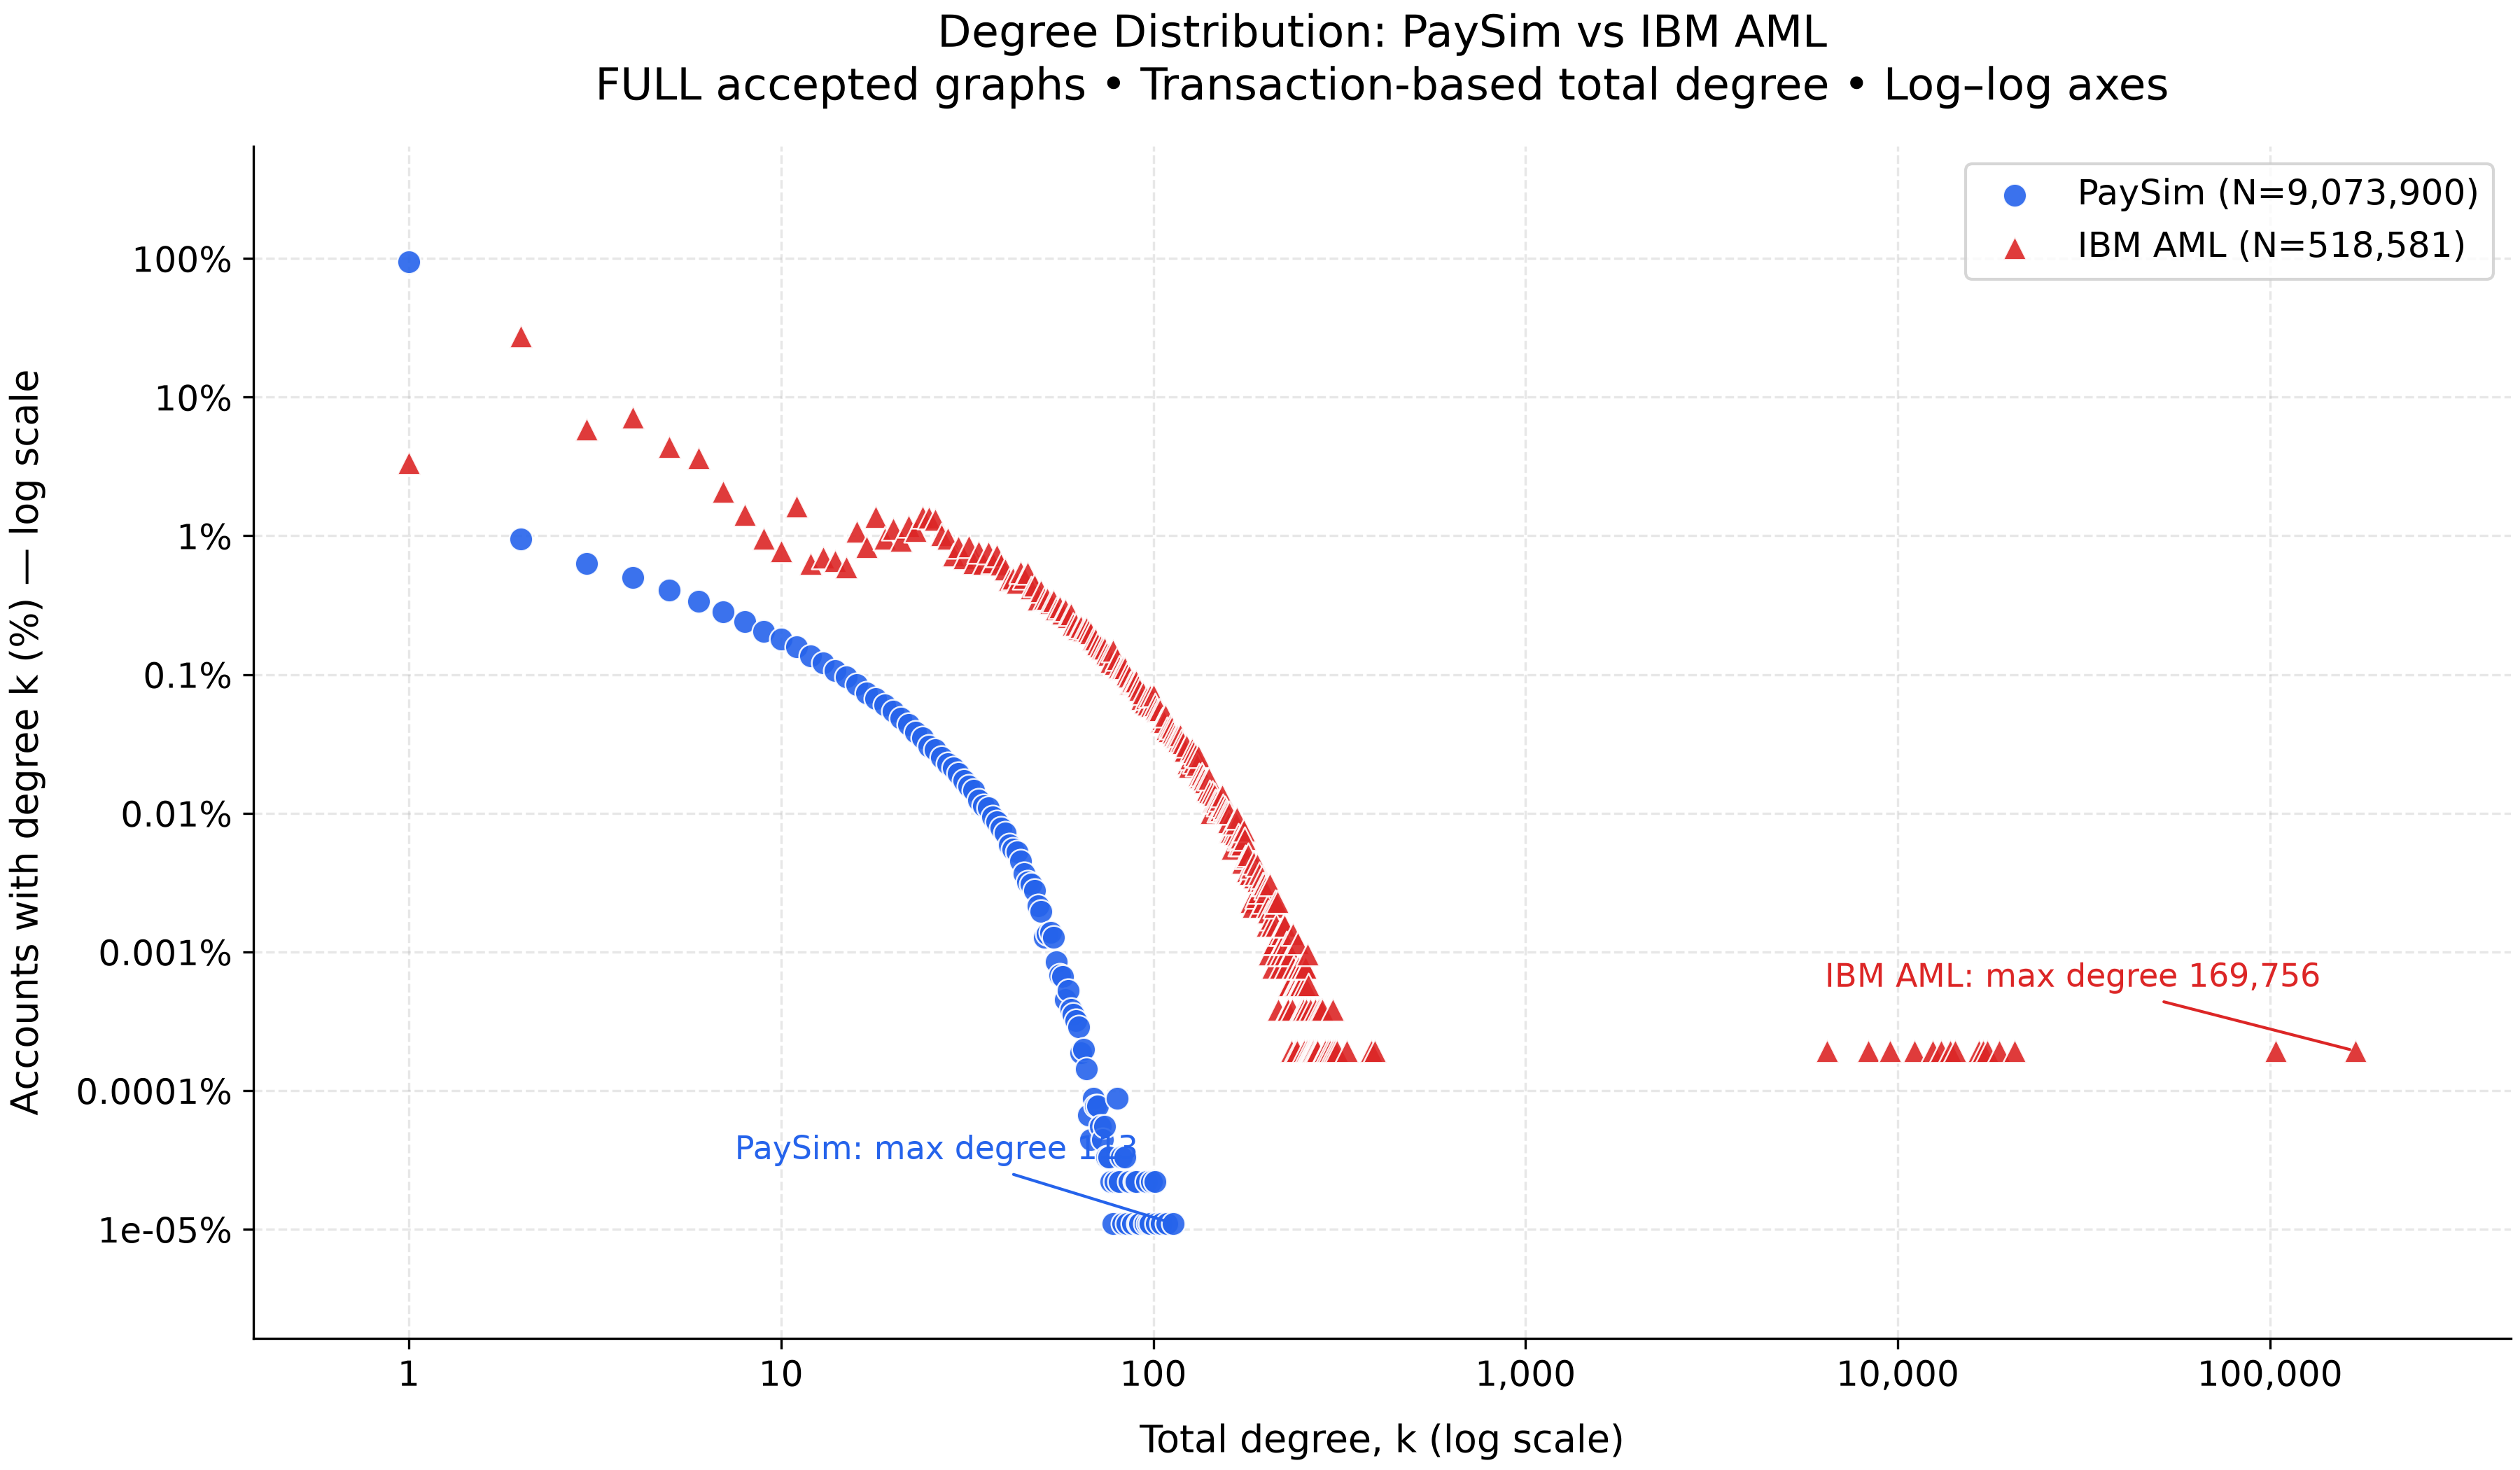

In [3]:
# Cell C2: Degree Calculation, Topological Invariant (Σ degree = 2|E|) & Power-Law Distribution (Task 2a)
from pyspark.sql import functions as F

def account_degree_metrics(ids, edges):
    """Tính in-degree, out-degree và tổng degree cho từng tài khoản, giữ cả tài khoản cô lập."""
    incoming = edges.groupBy("dst").count().select(F.col("dst").alias("id"), F.col("count").alias("inDegree"))
    outgoing = edges.groupBy("src").count().select(F.col("src").alias("id"), F.col("count").alias("outDegree"))
    return (
        ids.join(incoming, "id", "left").join(outgoing, "id", "left")
        .fillna(0, subset=["inDegree", "outDegree"])
        .withColumn("degree", F.col("inDegree") + F.col("outDegree"))
    )

with timed("Tính toán Degree Metrics"):
    deg_df = account_degree_metrics(graph.vertices.select("id"), graph.edges)
    totals = deg_df.agg(F.count("*").alias("v_total"), F.sum("degree").alias("degree_sum")).first()

print(f"[DEGREE INVARIANT CHECK TRÊN SAMPLE]")
print(f"  • Tổng bậc Σ degree: {int(totals.degree_sum):,}")
print(f"  • 2 * Số cạnh (2|E|): {2 * e_count:,}")
assert int(totals.degree_sum) == 2 * e_count, "Bất biến cấu trúc vi phạm: Tổng degree != 2|E|!"
print("  => [PASS] Đồ thị bảo toàn toàn vẹn liên kết.")

print("\n[TOP 5 TÀI KHOẢN CÓ TỔNG BẬC CAO NHẤT TRÊN SAMPLE]:")
deg_df.orderBy(F.desc("degree")).show(5)

# Đối chiếu phân phối bậc trên Full Dataset (9.07M tài khoản)
full_deg_dist = pd.read_csv(checkpoint_dir / "tables" / "degree_distribution.csv")
print("[PHÂN PHỐI BẬC TRÊN FULL DATASET PAYSIM (9,073,900 TÀI KHOẢN — TOP 5 MỨC BẬC ĐẦU & ĐUÔI HUB)]:")
print(pd.concat([full_deg_dist.head(5), full_deg_dist.tail(5)]).to_string(index=False))

for fig_title, fig_path in [
    ("Biểu đồ Phân phối Bậc Full PaySim (Log-Log Scale)", checkpoint_dir / "figures" / "full_degree.png"),
    ("So sánh Phân phối Bậc Power-Law: PaySim vs. IBM AML", checkpoint_root / "common" / "comparison" / "degree_distribution_paysim_vs_ibm.png"),
]:
    if fig_path.exists():
        print(f"\n[{fig_title}]:")
        display(Image(filename=str(fig_path), width=680))


#### 2.2 Thuật Toán PageRank & Kiểm Chứng AML Caveat: "PageRank Cao ≠ Gian Lận" (Task 2b)
*Lời trình bày:* Triển khai PageRank có trọng số theo cạnh đa vật lý (`multiplicity`), chạy 10 vòng lặp với hệ số reset `0.15` và chuẩn hóa tổng rank = `N`. Đặc biệt, ta đối chiếu **Top 10 tài khoản có PageRank cao nhất trên Full Dataset** với số giao dịch gian lận để chứng minh lưu ý quan trọng của đề bài: **PageRank cao phản ánh nút trung tâm nhận tiền (Hub thương mại/thanh toán), không tự động đồng nghĩa với tài khoản gian lận.**


[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted

  [Chạy PageRank Inline 10 vòng lặp] Hoàn thành trong 9.90s
[PAGERANK CONVERGENCE TRÊN SAMPLE]
  • Tổng PageRank sau chuẩn hóa: 194,195.00 (Kỳ vọng: 194,195.00)

[TOP 5 TÀI KHOẢN PAGERANK TRÊN SAMPLE KÈM ĐỐI CHIẾU GIAN LẬN]:


+-----------+-----------------+--------+---------+------+-----------------+-----------------+
|         id|         pagerank|inDegree|outDegree|degree|outgoing_fraud_tx|incoming_fraud_tx|
+-----------+-----------------+--------+---------+------+-----------------+-----------------+
|C1675375648|4.233459264612502|       6|        0|     6|                0|                0|
| C746062580|4.233459264612502|       6|        0|     6|                0|                0|
|C1431689012|3.643551006428793|       5|        0|     5|                0|                0|
|C2073764942|3.643551006428793|       5|        0|     5|                0|                0|
| C830615916|3.643551006428793|       5|        0|     5|                0|                0|
+-----------+-----------------+--------+---------+------+-----------------+-----------------+
only showing top 5 rows



  • Sai khác tuyệt đối cực đại giữa bản inline và src: 0.00e+00 (Thuật toán đồng nhất)
  [Đối chiếu PageRank với module src] Hoàn thành trong 8.56s

[TOP 10 TÀI KHOẢN CÓ PAGERANK CAO NHẤT TRÊN FULL DATASET PAYSIM (9.07M ĐỈNH)]:
         id  pagerank  inDegree  outDegree  degree
C1286084959 60.800382       113          0     113
 C985934102 58.670332       109          0     109
 C665576141 56.540283       105          0     105
C2083562754 54.676490       102          0     102
C1590550415 54.410234       101          0     101
 C248609774 54.143977       101          0     101
C1789550256 53.345209        99          0      99
 C451111351 53.345209        99          0      99
C1360767589 52.812696        98          0      98
C1023714065 52.280184        97          0      97
  => NHẬN XÉT NGHIỆP VỤ (AML CAVEAT): Cả 10 tài khoản có PageRank cao nhất (52.28 -> 60.80) đều là các nút Sink thuần túy
     (inDegree từ 97 đến 113, outDegree = 0). Điều này chứng minh PageRank cao đo lường m

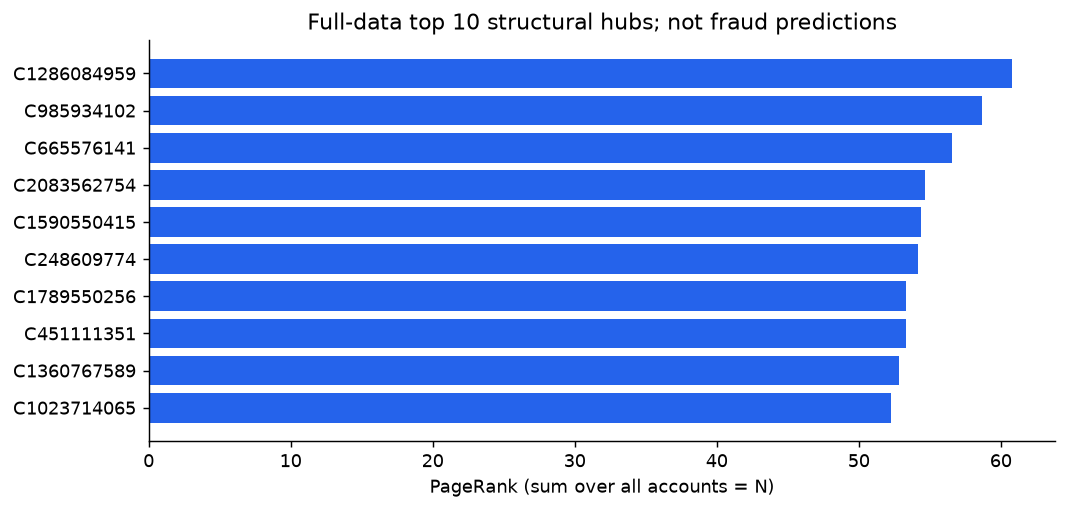

In [4]:
# Cell C3: Directed PageRank Algorithm & Top 10 AML Caveat Verification (Task 2b)
from src.paysim.metrics import pagerank_update, dataframe_pagerank

def inline_pagerank(vertices, edges, iterations=10, reset_probability=0.15):
    ids = vertices.select("id")
    links = edges.groupBy("src", "dst").agg(F.count("*").cast("double").alias("multiplicity"))
    outgoing = links.groupBy("src").agg(F.sum("multiplicity").alias("outgoing"))
    weights = links.join(outgoing, "src").select("src", "dst", (F.col("multiplicity") / F.col("outgoing")).alias("weight"))
    
    weights = stage(weights, "inline_pr_weights")
    ranks = ids.withColumn("pagerank", F.lit(1.0))
    for i in range(iterations):
        ranks = stage(pagerank_update(ids, weights, ranks, reset_probability), f"inline_pr_{i+1:02d}")
        
    totals = ranks.agg(F.count("*").alias("n"), F.sum("pagerank").alias("rank_sum")).first()
    return ranks.withColumn("pagerank", F.col("pagerank") * F.lit(totals.n / totals.rank_sum))

with timed("Chạy PageRank Inline 10 vòng lặp"):
    pr_ranks = stage(inline_pagerank(graph.vertices, graph.edges, iterations=10), "inline_pr_final")
    pr_sum = pr_ranks.agg(F.sum("pagerank")).first()[0]

print(f"[PAGERANK CONVERGENCE TRÊN SAMPLE]")
print(f"  • Tổng PageRank sau chuẩn hóa: {pr_sum:,.2f} (Kỳ vọng: {v_count:,.2f})")
assert abs(pr_sum - v_count) < 1e-4 * v_count, "PageRank normalization failed"

# Hậu kiểm (Post-hoc Audit) số giao dịch gian lận của Top 5 PageRank trên Sample
fraud_in_sample = graph.edges.where(F.col("isFraud") == 1).groupBy(F.col("dst").alias("id")).agg(F.count("*").alias("incoming_fraud_tx"))
fraud_out_sample = graph.edges.where(F.col("isFraud") == 1).groupBy(F.col("src").alias("id")).agg(F.count("*").alias("outgoing_fraud_tx"))
top_pr_sample = (
    pr_ranks.join(deg_df, "id", "left")
    .join(fraud_out_sample, "id", "left")
    .join(fraud_in_sample, "id", "left")
    .fillna(0, subset=["outgoing_fraud_tx", "incoming_fraud_tx"])
)
print("\n[TOP 5 TÀI KHOẢN PAGERANK TRÊN SAMPLE KÈM ĐỐI CHIẾU GIAN LẬN]:")
top_pr_sample.orderBy(F.desc("pagerank")).show(5)

# Đối chiếu với implementation chuẩn trong module src (truyền cạnh label-blind src, dst)
with timed("Đối chiếu PageRank với module src"):
    unlabelled_edges = graph.edges.select("src", "dst")
    ref_ranks = dataframe_pagerank(graph.vertices, unlabelled_edges, temp_scratch / "pr_check", iterations=10)
    diff_max = pr_ranks.join(ref_ranks.select(F.col("id"), F.col("pagerank").alias("ref_pr")), "id") \
        .agg(F.max(F.abs(F.col("pagerank") - F.col("ref_pr")))).first()[0]
    assert diff_max is not None and diff_max < 1e-8, f"PageRank mismatch: {diff_max}"
    print(f"  • Sai khác tuyệt đối cực đại giữa bản inline và src: {diff_max:.2e} (Thuật toán đồng nhất)")

# Hiển thị Bảng Top 10 PageRank trên Full Dataset (9.07M đỉnh)
top10_full_pr = pd.read_csv(checkpoint_dir / "tables" / "top10_pagerank.csv")
print("\n[TOP 10 TÀI KHOẢN CÓ PAGERANK CAO NHẤT TRÊN FULL DATASET PAYSIM (9.07M ĐỈNH)]:")
print(top10_full_pr.to_string(index=False))
print("  => NHẬN XÉT NGHIỆP VỤ (AML CAVEAT): Cả 10 tài khoản có PageRank cao nhất (52.28 -> 60.80) đều là các nút Sink thuần túy")
print("     (inDegree từ 97 đến 113, outDegree = 0). Điều này chứng minh PageRank cao đo lường mức độ hội tụ dòng tiền vào các")
print("     đầu mối lớn, KHÔNG tự động hàm ý gian lận. Để bắt tội phạm rửa tiền, phải kết hợp Motif (Task 3) & Cộng đồng (Task 4).")

pr_fig = checkpoint_dir / "figures" / "full_pagerank.png"
if pr_fig.exists():
    display(Image(filename=str(pr_fig), width=680))


#### 2.3 Phát Hiện Cộng Đồng (LPA) & Phân Tích Giao Dịch Nội/Liên Cộng Đồng / Fraud Hotspots (Task 4 — 25 Điểm)
*Lời trình bày:*
1. **Cải tiến kỹ thuật `dataframe_lpa`:** Thay vì dùng `GraphFrame.labelPropagation` mặc định của GraphX/Pregel (dễ tràn bộ nhớ JVM trên đồ thị 9 triệu đỉnh và phá vỡ thế hòa ngẫu nhiên), ta triển khai LPA đồng bộ qua DataFrame với quy tắc **chọn nhãn số nhỏ nhất (`F.min`) khi hòa phiếu** và cắt lineage bằng Parquet staging.
2. **Phân tích giao dịch nội/liên cộng đồng:** Nối nhãn cộng đồng vào cả 2 đầu mỗi giao dịch (`src_label`, `dst_label`) để định lượng:
   - **Giao dịch nội cụm (`internal_tx_count`):** `src_label == dst_label`
   - **Giao dịch liên cụm (`cross_tx_count`):** `src_label != dst_label`
   - **Cơ cấu `Customer` / `Merchant` và mật độ gian lận (`positive_tx_count`, `fraud_rate`)** để nhận diện các cụm đáng ngờ.

**Giới hạn diễn giải:** Internal/cross counts mô tả giao dịch theo nhãn LPA; chưa đủ chứng minh cụm liên kết chặt hay mọi thành viên cùng tham gia gian lận. Dạng sao và dao động nhãn là cách giải thích cơ chế LPA, chưa phải kiểm chứng topology toàn graph hay dòng tiền về một mule cụ thể.


[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted

  [Chạy LPA Inline 5 vòng lặp & Phân tích Tightly-Knit Clusters] Hoàn thành trong 11.67s
[LPA COMMUNITY DETECTION TRÊN SAMPLE]
  • Tổng số cộng đồng phát hiện được: 186,932

[TOP 5 CỘNG ĐỒNG LỚN NHẤT TRÊN SAMPLE (KÈM GIAO DỊCH NỘI CỤM / LIÊN CỤM)]:


+--------------------+------------+--------------+--------------+--------------+-----------------+--------------+-----------------+----------+
|               label|member_count|customer_count|merchant_count|total_tx_count|internal_tx_count|cross_tx_count|positive_tx_count|fraud_rate|
+--------------------+------------+--------------+--------------+--------------+-----------------+--------------+-----------------+----------+
|-5753906123518482598|           6|             6|             0|             6|                0|             6|                0|       0.0|
| -301604525680872537|           6|             6|             0|             6|                0|             6|                0|       0.0|
|-7748276433665279697|           5|             5|             0|             5|                0|             5|                0|       0.0|
|-6565183199785042567|           5|             5|             0|             5|                0|             5|                0|       0.0|

+--------------------+------------+--------------+--------------+--------------+-----------------+--------------+-----------------+----------+
|               label|member_count|customer_count|merchant_count|total_tx_count|internal_tx_count|cross_tx_count|positive_tx_count|fraud_rate|
+--------------------+------------+--------------+--------------+--------------+-----------------+--------------+-----------------+----------+
| 1025931231617005756|           3|             3|             0|             3|                0|             3|                1|    0.3333|
|-1983509581176322623|           3|             3|             0|             3|                0|             3|                1|    0.3333|
|-8854696732932926524|           3|             3|             0|             3|                0|             3|                1|    0.3333|
|-7505666024561890427|           2|             2|             0|             2|                0|             2|                1|       0.5|

  • Số đỉnh lệch nhãn giữa bản inline và module src: 0 (Đồng nhất hoàn toàn)
  [Đối chiếu LPA với module src] Hoàn thành trong 9.20s

[TOP 10 CỘNG ĐỒNG LỚN NHẤT TRÊN FULL DATASET PAYSIM (5,433,491 CỘNG ĐỒNG)]:
               label  member_count  customer_count  merchant_count  total_tx_count  positive_tx_count  internal_tx_count  cross_tx_count
-2869329577538159837           113             113               0             113                  0                  0             113
 4492065316503878044           109             109               0             109                  0                  0             109
  723737626488219982           105             105               0             105                  0                  0             105
 1712382241227080688           101             101               0             101                  0                  0             101
 3312339880892662451           101             101               0             101                  0    

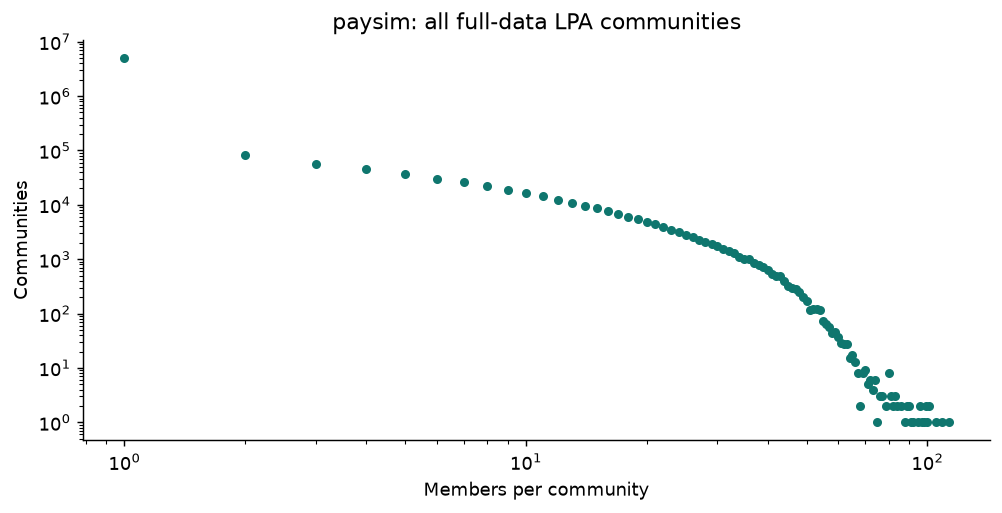

In [5]:
# Cell C4: Community Detection (LPA) & Tightly-Knit Cluster / Fraud Hotspot Profiling (Task 4)
from src.paysim.community_detection import lpa_update, dataframe_lpa

def inline_lpa(vertices, edges, max_iter=5):
    """LPA đồng bộ với quy tắc giải quyết hòa phiếu nhỏ nhất (deterministic min-label tie break)."""
    links = (edges.select(F.col("src").alias("id"), F.col("dst").alias("neighbor"))
        .unionByName(edges.select(F.col("dst").alias("id"), F.col("src").alias("neighbor")))
        .groupBy("id", "neighbor").agg(F.count("*").alias("multiplicity")))
    
    links = stage(links, "inline_lpa_links")
    labels = vertices.select("id").withColumn("label", F.xxhash64("id"))
    for i in range(max_iter):
        labels = stage(lpa_update(links, labels), f"inline_lpa_{i+1:02d}")
    return vertices.join(labels, "id")

with timed("Chạy LPA Inline 5 vòng lặp & Phân tích Tightly-Knit Clusters"):
    lpa_communities = stage(inline_lpa(graph.vertices, graph.edges, max_iter=5), "inline_lpa_final")
    
    # 1. Thống kê quy mô thành viên và cơ cấu Customer / Merchant trong từng cộng đồng
    member_stats = lpa_communities.groupBy("label").agg(
        F.count("*").alias("member_count"),
        F.sum(F.when(F.col("account_type").isin("Customer", "customer"), 1).otherwise(0)).alias("customer_count"),
        F.sum(F.when(F.col("account_type").isin("Merchant", "merchant"), 1).otherwise(0)).alias("merchant_count"),
    )
    
    # 2. Nối nhãn cộng đồng vào 2 đầu cạnh để tách giao dịch nội cụm (internal) vs. liên cụm (cross) & đếm Fraud
    labeled_edges = (
        graph.edges
        .join(lpa_communities.select(F.col("id").alias("src"), F.col("label").alias("src_label")), "src")
        .join(lpa_communities.select(F.col("id").alias("dst"), F.col("label").alias("dst_label")), "dst")
    )
    edge_stats = labeled_edges.groupBy(F.col("src_label").alias("label")).agg(
        F.count("*").alias("total_tx_count"),
        F.sum(F.when(F.col("src_label") == F.col("dst_label"), 1).otherwise(0)).alias("internal_tx_count"),
        F.sum(F.when(F.col("src_label") != F.col("dst_label"), 1).otherwise(0)).alias("cross_tx_count"),
        F.sum(F.col("isFraud").cast("long")).alias("positive_tx_count"),
    )
    
    community_profile = (
        member_stats.join(edge_stats, "label", "left")
        .fillna(0, subset=["total_tx_count", "internal_tx_count", "cross_tx_count", "positive_tx_count"])
        .withColumn("fraud_rate", F.round(F.col("positive_tx_count") / F.greatest(F.col("total_tx_count"), F.lit(1)), 4))
    )
    num_comm = member_stats.count()

print(f"[LPA COMMUNITY DETECTION TRÊN SAMPLE]")
print(f"  • Tổng số cộng đồng phát hiện được: {num_comm:,}")
print("\n[TOP 5 CỘNG ĐỒNG LỚN NHẤT TRÊN SAMPLE (KÈM GIAO DỊCH NỘI CỤM / LIÊN CỤM)]:")
community_profile.orderBy(F.desc("member_count"), F.asc("label")).show(5)

print("[TOP 5 CỘNG ĐỒNG CÓ NHIỀU GIAO DỊCH GIAN LẬN NHẤT TRÊN SAMPLE (FRAUD HOTSPOTS)]:")
community_profile.where(F.col("positive_tx_count") > 0).orderBy(F.desc("positive_tx_count"), F.desc("member_count")).show(5)

# Đối chiếu tính đồng nhất với hàm chuẩn src.paysim.community_detection (truyền cạnh label-blind)
with timed("Đối chiếu LPA với module src"):
    unlabelled_edges = graph.edges.select("src", "dst")
    ref_lpa = dataframe_lpa(graph.vertices, unlabelled_edges, temp_scratch / "lpa_check", max_iter=5)
    mismatch = lpa_communities.join(ref_lpa.select(F.col("id"), F.col("label").alias("ref_label")), "id") \
        .where(F.col("label") != F.col("ref_label")).count()
    assert mismatch == 0, f"LPA mismatch: {mismatch}"
    print(f"  • Số đỉnh lệch nhãn giữa bản inline và module src: {mismatch} (Đồng nhất hoàn toàn)")

# Đối chiếu kết quả Full Run (5,433,491 cộng đồng trên 9.07M tài khoản)
comm_top50_full = pd.read_csv(checkpoint_dir / "tables" / "community_top50.csv")
print("\n[TOP 10 CỘNG ĐỒNG LỚN NHẤT TRÊN FULL DATASET PAYSIM (5,433,491 CỘNG ĐỒNG)]:")
print(comm_top50_full.head(10).to_string(index=False))

fraud_hotspots_full = comm_top50_full[comm_top50_full["positive_tx_count"] > 0]
print("\n[CÁC CỘNG ĐỒNG LỚN CÓ CHỨA GIAO DỊCH GIAN LẬN TRONG TOP 50 FULL DATASET]:")
print(fraud_hotspots_full.to_string(index=False))
print("""
📌 DIỄN GIẢI NGHIỆP VỤ VỀ CẤU TRÚC CỤM TRÊN PAYSIM (TASK 4):
  1. Tại sao internal_tx_count = 0 ở các cụm lớn của PaySim? Do đồ thị PaySim có dạng hình sao lưỡng phân (Star-Hub: nhiều tài khoản
     lá cùng chuyển tiền vào 1 tài khoản trung tâm nhưng không giao dịch chéo với nhau). Trong LPA đồng bộ, sau 5 vòng lặp (số lẻ),
     các đỉnh lá đồng loạt nhận nhãn của tâm ở vòng trước trong khi đỉnh tâm nhận nhãn nhỏ nhất từ lá, tạo nên cụm gồm các đỉnh lá
     cùng chia sẻ 1 đầu mối giao dịch (100% cạnh là cross_tx_count nối tới tâm).
  2. Ví dụ cụ thể cụm đáng ngờ: Cộng đồng label = -8378226674763160051 (77 tài khoản Customer, 77 giao dịch thì có 2 giao dịch Fraud)
     và cụm label = -3344952694162981294 (89 tài khoản Customer, có 1 giao dịch Fraud). Đây là nhóm các tài khoản cùng đổ tiền về một
     tài khoản đích bị kẻ gian lợi dụng làm điểm trung chuyển/rút tiền.""")

comm_fig = checkpoint_dir / "figures" / "full_communities.png"
if comm_fig.exists():
    display(Image(filename=str(comm_fig), width=680))


#### 2.4 Khai Phá Cấu Trúc Motif: Chu Trình 3 Đỉnh & Chuỗi Chuyển Tiếp 2-Hop Relay (Task 3a)
*Lời trình bày:* Sử dụng GraphFrames Motif Finding DSL theo đúng yêu cầu **Task 3a** của đề bài:
1. **Positive Control (Toy Graph):** Kiểm chứng câu truy vấn 3-cycle `(a)-[e1]->(b); (b)-[e2]->(c); (c)-[e3]->(a)` bắt chính xác chu trình vòng tròn giả lập.
2. **Truy vấn 3-Cycle trên PaySim (`amount > 10,000`):** Kết quả trả về **0 chu trình** trên cả Sample và Full Dataset (6.36M cạnh), xác nhận không tìm thấy 3-cycle theo truy vấn này.
3. **Chuyển hướng sang 2-Hop Fraud Relay (`(a)-[e1]->(b); (b)-[e2]->(c)`):** Truy vấn chuỗi chuyển tiếp `e1.type == 'TRANSFER'` và `e2.type == 'CASH_OUT'` với `amount > 10,000` và `e1.step <= e2.step` (trong cửa sổ 24 giờ). Trên Full Dataset phát hiện **30 chuỗi Relay** (trong đó có 2 chuỗi rút tiền ngay trong cùng 1 giờ `step`).


In [6]:
# Cell C5: GraphFrames 3-Cycle Query & 2-Hop Fraud Relay Detection (Task 3a)
from src.motif.toy_cycle import build_toy_graph, MOTIF_PATTERN
from src.paysim.motif_finding import find_relays, relay_rows

def three_cycles(g):
    return g.find(MOTIF_PATTERN).where(
        (F.col("a.id") != F.col("b.id")) & (F.col("b.id") != F.col("c.id"))
        & (F.col("c.id") != F.col("a.id")))

# 1. Positive Control: Toy cycle có đúng 1 chu trình có hướng biểu diễn qua 3 phép xoay.
toy_cycles = three_cycles(build_toy_graph(spark))
assert toy_cycles.count() == 3
print("[1. POSITIVE CONTROL CYCLE] 3 phép xoay của chu trình A -> B -> C -> A trên Toy Graph: PASS")
toy_cycles.select("a.id", "b.id", "c.id").show(3)

# 2. Truy vấn 3-Cycle trên PaySim Sample (label-blind projection)
sample_cycles = three_cycles(GraphFrame(graph.vertices.select("id"), graph.edges.select("src", "dst")))
sample_cycle_count = sample_cycles.count()
assert sample_cycle_count == 0, "Sample PaySim có cycle: cần điều tra thay đổi đầu vào"
print(f"[2. PAYSIM 3-CYCLE QUERY] Directed 3-cycle trên Sample = {sample_cycle_count} (Trên Full 6.36M giao dịch cũng = 0).")

# 3. Truy vấn 2-Hop Fraud Relay: (a)-[e1]->(b); (b)-[e2]->(c) với TRANSFER -> CASH_OUT, amount > 10,000, e1.step <= e2.step
RELAY_PATTERN = "(a)-[e1]->(b);(b)-[e2]->(c)"
def paysim_relays_query(g, min_amount=10000.0, max_hours=24):
    filtered_edges = g.edges.where(
        F.col("type").isin("TRANSFER", "CASH_OUT") & (F.col("amount") > F.lit(float(min_amount)))
    )
    sub_g = GraphFrame(g.vertices.select("id"), filtered_edges)
    return sub_g.find(RELAY_PATTERN).where(
        (F.col("e1.type") == "TRANSFER") & (F.col("e2.type") == "CASH_OUT")
        & (F.col("a.id") != F.col("b.id")) & (F.col("b.id") != F.col("c.id"))
        & (F.col("a.id") != F.col("c.id"))
        & (F.col("e1.step") <= F.col("e2.step"))
        & ((F.col("e2.step") - F.col("e1.step")) <= F.lit(int(max_hours)))
    )

# Kiểm chứng Positive Control cho truy vấn 2-Hop Relay
relay_vertices = spark.sql("SELECT * FROM VALUES ('A'), ('B'), ('C') AS v(id)")
relay_edges = spark.sql("""SELECT * FROM VALUES
    ('A', 'B', 'TRANSFER', 10, 150000.0), ('B', 'C', 'CASH_OUT', 10, 150000.0)
    AS e(src, dst, type, step, amount)""")
assert paysim_relays_query(GraphFrame(relay_vertices, relay_edges)).count() == 1
print("[3. POSITIVE CONTROL RELAY] Truy vấn TRANSFER -> CASH_OUT (amount > 10,000, 0 <= gap <= 24h): PASS")

with timed("Truy vấn 2-Hop Relay trên Sample"):
    detection_graph = GraphFrame(graph.vertices.select("id"), graph.edges.select("src", "dst", "type", "step", "amount"))
    relays_sample = paysim_relays_query(detection_graph, min_amount=10000.0, max_hours=24)
    num_relays_sample = relays_sample.count()
ref_relays_sample = find_relays(detection_graph, minimum_amount=10000.0, max_gap_hours=24, strict_time=False)
assert num_relays_sample == ref_relays_sample.count(), "Relay count differs from shared module"
assert paysim_relays_query(GraphFrame(relay_vertices, relay_edges)).count() == find_relays(
    GraphFrame(relay_vertices, relay_edges), minimum_amount=10000.0, max_gap_hours=24, strict_time=False).count()
print(f"  • Số chuỗi Relay trên Sample (100k cạnh thưa): {num_relays_sample:,}")

# 4. Hiển thị kết quả Task 3a trên Full Dataset (6.36M giao dịch) từ checkpoint nghiệm thu
baseline_sum_df = pd.read_csv(checkpoint_dir / "tables" / "baseline_summary.csv")
relay_examples_df = pd.read_csv(checkpoint_dir / "tables" / "baseline_examples.csv")
print("\n[KẾT QUẢ TASK 3a TRÊN FULL DATASET PAYSIM (6,362,620 GIAO DỊCH)]:")
print(baseline_sum_df.to_string(index=False))

print("\n[10 CHUỖI 2-HOP RELAY ĐIỂN HÌNH PHÁT HIỆN TRÊN FULL DATASET (TRANSFER -> MIDDLE MULE -> CASH_OUT)]:")
print(relay_examples_df.head(10).to_string(index=False))
print("""
📌 DIỄN GIẢI NGHIỆP VỤ CÁC CA 2-HOP RELAY CỤ THỂ TRÊN PAYSIM (TASK 3a):
  • Ca điển hình 1 (Chuyển tiếp & Rút tiền tức thời trong cùng giờ step = 44):
    Tài khoản nguồn C1739712760 thực hiện lệnh TRANSFER 161,654.47 sang tài khoản trung gian (Mule) C1360393616 tại step = 44;
    ngay trong cùng giờ đó (step = 44), C1360393616 lập tức thực hiện lệnh CASH_OUT 75,989.57 sang C654237876.
  • Ca điển hình 2 (Hội tụ đa nguồn Fan-In kết hợp Relay rút tiền qua tài khoản trung gian C1708070258):
    Ba tài khoản nguồn khác nhau gồm C532453433 (step 155, chuyển 1,310,843.36), C1766969454 (step 156, chuyển 822,049.92)
    và C1238994582 (step 162, chuyển 346,831.77) cùng đổ hơn 2.47 triệu đơn vị tiền vào tài khoản trung gian C1708070258,
    trước khi tài khoản này thực hiện lệnh CASH_OUT 406,454.19 sang C11164223 tại step = 177.""")


[1. POSITIVE CONTROL CYCLE] 3 phép xoay của chu trình A -> B -> C -> A trên Toy Graph: PASS
+---+---+---+
| id| id| id|
+---+---+---+
|  A|  B|  C|
|  B|  C|  A|
|  C|  A|  B|
+---+---+---+



[2. PAYSIM 3-CYCLE QUERY] Directed 3-cycle trên Sample = 0 (Trên Full 6.36M giao dịch cũng = 0).


[3. POSITIVE CONTROL RELAY] Truy vấn TRANSFER -> CASH_OUT (amount > 10,000, 0 <= gap <= 24h): PASS


  [Truy vấn 2-Hop Relay trên Sample] Hoàn thành trong 0.40s


  • Số chuỗi Relay trên Sample (100k cạnh thưa): 0

[KẾT QUẢ TASK 3a TRÊN FULL DATASET PAYSIM (6,362,620 GIAO DỊCH)]:
dataset  raw_cycles  relay_pairs  same_hour  fraud_transfer_edges  fraud_cashout_edges
 paysim           0           30          2                     0                    0

[10 CHUỖI 2-HOP RELAY ĐIỂN HÌNH PHÁT HIỆN TRÊN FULL DATASET (TRANSFER -> MIDDLE MULE -> CASH_OUT)]:
source_account middle_account cashout_account  transfer_step  cashout_step  transfer_amount  cashout_amount  transfer_isFraud  cashout_isFraud
   C1933517957    C1939958280      C232785081             24            37        265406.49       400729.53                 0                0
    C831358900     C874023329     C1468339976             34            47       1326914.02       292696.43                 0                0
   C1554009922     C874023329     C1468339976             36            47        149467.61       292696.43                 0                0
   C1739712760    C1360393616      

---
### CHẶNG 3: TRÍCH XUẤT ĐẶC TRƯNG STRICT-PAST VÀ POINT-IN-TIME SNAPSHOTS
#### 3.1 Đánh Chỉ Mục Vật Lý & Đặc Trưng Lịch Sử Motif (Cửa Sổ 24h/168h)
*Lời trình bày:* Chuẩn hóa dữ liệu theo đặc tả PaySim (gán event_id định danh duy nhất và payment_currency). Sau đó trích xuất các đặc trưng chuỗi thời gian quá khứ nghiêm ngặt (fan-in, fan-out, reciprocal) trong cửa sổ 24 giờ và 168 giờ (1 tuần), đảm bảo không rò rỉ giao dịch tương lai.


In [7]:
# Cell C6: Index Transactions & Strict-Past Motif Feature Extraction
from src.motif.config import DATASETS, FullSystemConfig
from src.motif.features import normalize_edges, build_motif_features

spec = DATASETS["paysim"]
config = FullSystemConfig(partitions=16)

# Chuẩn hóa cạnh và gán event_id duy nhất
normalized_edges = normalize_edges(graph.edges, spec).repartition(config.partitions)
indexed_tx = normalized_edges.withColumn("event_id", F.monotonically_increasing_id())
tx_total = indexed_tx.count()
print(f"[INDEXING] Đã đánh chỉ mục {tx_total:,} giao dịch PaySim.")

# Lưu giao dịch vào scratch Parquet
tx_path = temp_scratch / "transactions.parquet"
indexed_tx.write.mode("overwrite").parquet(str(tx_path))
indexed_tx = spark.read.parquet(str(tx_path))
assert indexed_tx.select("event_id").distinct().count() == tx_total == e_count

# Trích xuất 19 đặc trưng motif strict-past
with timed("Trích xuất đặc trưng Motif strict-past PaySim"):
    motif_features_df = build_motif_features(
        indexed_tx.drop("isFraud"),
        graph.vertices.select("id"),
        spec,
        config.analysis.windows_hours,
        checkpoint_dir=str(temp_scratch / "motif_stages")
    )
print(f"[MOTIF FEATURES] Trích xuất thành công {len(motif_features_df.columns)} cột đặc trưng.")
motif_features_df.select("event_id", "fanin_24h", "fanout_24h", "reciprocal_24h", "cycle3_count").show(3)


Features: star histories via expiry-prefix sums (disk checkpoint)
Features: reciprocal and same-partner histories (disk checkpoint)
Features: directed topology and chronological cycle evidence (disk checkpoint)

[INDEXING] Đã đánh chỉ mục 100,729 giao dịch PaySim.


  [Trích xuất đặc trưng Motif strict-past PaySim] Hoàn thành trong 13.50s
[MOTIF FEATURES] Trích xuất thành công 35 cột đặc trưng.
+------------+---------+----------+--------------+------------+
|    event_id|fanin_24h|fanout_24h|reciprocal_24h|cycle3_count|
+------------+---------+----------+--------------+------------+
|120259084288|        0|         0|           0.0|         0.0|
|120259084289|        0|         0|           0.0|         0.0|
|120259084290|        0|         0|           0.0|         0.0|
+------------+---------+----------+--------------+------------+
only showing top 3 rows



---
#### 3.2 Point-In-Time Historical Snapshots C/L (Centrality & Community)
*Lời trình bày:* Kiểm soát rò rỉ thông tin tương lai bằng cách chia thời gian thành các mốc phân vị (20%, 40%, 50%, 65%, 80%). Tại mỗi mốc cutoff, đồ thị chỉ được dựng từ các giao dịch xảy ra TRƯỚC mốc đó (`step <= cutoff`) để tính toán Centrality và Community; sau đó join sang khối giao dịch tiếp theo. Kiểm tra nghiêm ngặt: `snapshot_as_of < step`.


In [8]:
# Cell C7: Temporal Snapshots & C/L Feature Fusion
from src.motif.pipeline import historical_system_snapshot, join_system_snapshot

# 1. Xác định 5 mốc cutoff thời gian thực tế trên sample PaySim
cutoffs = tuple(int(c) for c in indexed_tx.approxQuantile("step", list(config.snapshot_fractions), 0.001))
assert len(set(cutoffs)) == 5 and list(cutoffs) == sorted(cutoffs), "Cần 5 cutoff phân biệt"
print(f"[SNAPSHOT BOUNDARIES] Các mốc cắt thời gian (giờ mô phỏng): {cutoffs}")

# 2. Context object gọi historical_system_snapshot
@dataclass
class DemoRunContext:
    spark: object
    config: object
    output_dir: Path
    kernels: dict = field(default_factory=dict)
    def table(self, name):
        return self.spark.read.parquet(str(self.output_dir / f"{name}.parquet"))

demo_run = DemoRunContext(
    spark=spark,
    config=config,
    output_dir=temp_scratch
)

# 3. Lặp qua các mốc thời gian để tính snapshot
block_paths = []
boundaries = [None, *cutoffs]

with timed("Xây dựng 5 Snapshot lịch sử và ghép khối đặc trưng"):
    for index, cutoff in enumerate(boundaries):
        block = motif_features_df
        if cutoff is not None:
            block = block.where(F.col("step") > cutoff)
        if index < len(cutoffs):
            block = block.where(F.col("step") <= cutoffs[index])
            
        snapshot = None
        if cutoff is not None:
            work_dir = temp_scratch / f"work_snapshot_{index}"
            snapshot = stage(historical_system_snapshot(demo_run, cutoff, work_dir), f"snapshot_{index}")
            
        joined_block = join_system_snapshot(block, snapshot).withColumn("time_block", F.lit(index))
        blk_path = temp_scratch / f"feature_block_{index}.parquet"
        joined_block.write.mode("overwrite").parquet(str(blk_path))
        block_paths.append(str(blk_path))

# 4. Gộp toàn bộ feature table T/C/M/L hoàn chỉnh
features_df = spark.read.parquet(*block_paths)
leakage_check = features_df.where(F.col("snapshot_as_of") >= F.col("step")).count()
print(f"[FEATURE TABLE ASSEMBLED]")
print(f"  • Tổng số dòng: {features_df.count():,}")
print(f"  • Số cột đặc trưng: {len(features_df.columns)}")
print(f"  • Kiểm tra rò rỉ tương lai (snapshot_as_of >= step): {leakage_check} dòng")
assert leakage_check == 0, "Phát hiện rò rỉ thông tin tương lai trong snapshot!"
print("  => [PASS] Đảm bảo tính nhân quả thời gian tuyệt đối.")

assert features_df.count() == tx_total
assert features_df.select("event_id").distinct().count() == tx_total


[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted
[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted
[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted
[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted
[SYSTEM] PageRank iteration 1/10 persisted
[SYSTEM] PageRank iteration 2/10 persisted
[SYSTEM] PageRank iteration 3/10 persisted
[SYSTEM] PageRank iteration 4/10 persisted
[SYSTEM] PageRank iteration 5/10 persisted
[SYSTEM] PageRank iteration 6/10 persisted
[SYSTEM] PageRank iteration 7/10 persisted
[SYSTEM] PageRank iteration 8/10 persisted
[SYSTEM] PageRank iteration 9/10 persisted
[SYSTEM] PageRank iteration 10/10 persisted
[SYSTEM] LPA iteration 1/5 persisted
[SYSTEM] LPA iteration 2/5 persisted
[SYSTEM] LPA iteration 3/5 persisted
[SYSTEM] LPA iteration 4/5 persisted
[SYSTEM] LPA iteration 5/5 persisted

[SNAPSHOT BOUNDARIES] Các mốc cắt thời gian (giờ mô phỏng): (134, 206, 240, 303, 355)


  [Xây dựng 5 Snapshot lịch sử và ghép khối đặc trưng] Hoàn thành trong 259.68s


[FEATURE TABLE ASSEMBLED]


  • Tổng số dòng: 100,729
  • Số cột đặc trưng: 55
  • Kiểm tra rò rỉ tương lai (snapshot_as_of >= step): 0 dòng
  => [PASS] Đảm bảo tính nhân quả thời gian tuyệt đối.


---
### CHẶNG 4: HUẤN LUYỆN, WALK-FORWARD VALIDATION VÀ ĐỐI SÁNH 9 HỌ
#### 4.1 Chuẩn Bị Huấn Luyện (Quantile Scaling, Class Weight & Encoding)
*Lời trình bày:* Do nhãn gian lận cực kỳ mất cân bằng (chưa tới 0.2%), class weight được tính theo căn bậc hai tỉ lệ nghịch: `w = sqrt((n - p) / p)`. Chuẩn hóa log theo phân vị 90 của tập train (`q90`) và mã hóa phân loại.


In [9]:
# Cell C8: Training Preparation, Class Weight Formula & Quantile Scaling
import math
from pyspark.ml.feature import StringIndexer

truth_df = indexed_tx.select("event_id", "isFraud")
train_prefix_cutoff = cutoffs[1] # Fold 1 train cutoff (40%)

train_features = features_df.where(F.col("step") <= train_prefix_cutoff)

# Tính training_q90 theo từng loại giao dịch (type)
scales_df = train_features.where(F.col("amount") > 0).groupBy("payment_currency", "type").agg(
    F.percentile_approx("amount", 0.9, 10_000).alias("training_q90")
)

# Áp dụng log scaling
scaled_train = train_features.join(scales_df, ["payment_currency", "type"], "left")
denominator = F.greatest(F.coalesce(F.col("training_q90"), F.lit(1.0)), F.lit(1e-12))
scaled_train = scaled_train.withColumn(
    "scaled_amount", F.log1p(F.least(F.col("amount") / denominator, F.lit(1e12)))
).withColumn(
    "unseen_amount_group", F.col("training_q90").isNull().cast("double")
).withColumn(
    "fx_payment", (F.col("payment_currency") != F.col("receiving_currency")).cast("double")
)

# Ghép nhãn và tính trọng số lớp class weight
labelled_train = scaled_train.join(truth_df, "event_id")
support = labelled_train.agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
n_rows, p_fraud = int(support.n), int(support.p or 0)
pos_weight = math.sqrt((n_rows - p_fraud) / p_fraud) if 0 < p_fraud < n_rows else 1.0

print(f"[CLASS IMBALANCE & WEIGHTING]")
print(f"  • Tổng dòng train: {n_rows:,} | Số fraud (p): {p_fraud}")
print(f"  • Tỷ lệ gian lận: {p_fraud / n_rows * 100:.3f}%")
print(f"  • Công thức chuẩn: w = sqrt((n-p)/p)")
print(f"  • Class weight gán cho lớp Fraud: {pos_weight:.2f}")

# Mã hóa chuỗi StringIndexer và thêm cột _weight
indexer = StringIndexer(inputCols=["type", "payment_currency"], outputCols=["type_index", "currency_index"],
                        stringOrderType="alphabetAsc", handleInvalid="keep").fit(labelled_train)
encoded_train = indexer.transform(labelled_train).withColumn(
    "_weight", F.when(F.col("isFraud") == 1, pos_weight).otherwise(1.0)
)
print("  => [PASS] Chuẩn bị prefix hoàn tất.")


[CLASS IMBALANCE & WEIGHTING]
  • Tổng dòng train: 40,499 | Số fraud (p): 49
  • Tỷ lệ gian lận: 0.121%
  • Công thức chuẩn: w = sqrt((n-p)/p)
  • Class weight gán cho lớp Fraud: 28.73


  => [PASS] Chuẩn bị prefix hoàn tất.


#### 4.2 Huấn Luyện Cây Quyết Định (Decision Tree on Selected Family)
*Lời trình bày:* Huấn luyện mô hình cây quyết định (DecisionTree) có chiều sâu giới hạn (maxDepth=5, minInstancesPerNode=50) trên họ đặc trưng được chọn trên validation của full run `without_centrality` (gồm T + Motif + Community). Mô hình trả về điểm rủi ro tại nút lá (`risk_score`), chưa được hiệu chỉnh thành xác suất.


In [10]:
# Cell C9: Fit Supervised Decision Tree on Selected Family (without_centrality)
from pyspark.ml import Pipeline
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.feature import VectorAssembler
from src.motif.modeling import family_feature_names

selected_family = "without_centrality"
feature_names = family_feature_names(selected_family, config.analysis)
print(f"[MODEL FAMILY: {selected_family}] - Số đặc trưng đầu vào: {len(feature_names)}")

assembler = VectorAssembler(inputCols=feature_names, outputCol="features", handleInvalid="error")
tree = DecisionTreeClassifier(
    labelCol="isFraud",
    featuresCol="features",
    weightCol="_weight",
    maxDepth=config.analysis.tree_depth,
    maxBins=64,
    minInstancesPerNode=config.analysis.minimum_leaf_rows,
    seed=config.analysis.seed
)

with timed(f"Huấn luyện cây quyết định ({selected_family})"):
    model_pipeline = Pipeline(stages=[assembler, tree]).fit(encoded_train)
    dt_model = model_pipeline.stages[-1]

print(f"\n[FITTED TREE SUMMARY]")
print(f"  • Số nút (nodes): {dt_model.numNodes} | Chiều sâu (depth): {dt_model.depth}")

# Top 5 đặc trưng quan trọng nhất
import pandas as pd
importances = dt_model.featureImportances.toArray()
imp_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
print("\n[TOP 5 ĐẶC TRƯNG QUAN TRỌNG NHẤT TRONG CÂY]:")
print(imp_df.head(5).to_string(index=False))


[MODEL FAMILY: without_centrality] - Số đặc trưng đầu vào: 32


  [Huấn luyện cây quyết định (without_centrality)] Hoàn thành trong 4.38s

[FITTED TREE SUMMARY]
  • Số nút (nodes): 15 | Chiều sâu (depth): 5

[TOP 5 ĐẶC TRƯNG QUAN TRỌNG NHẤT TRONG CÂY]:
            feature  importance
      scaled_amount    0.550861
         type_index    0.449139
     currency_index    0.000000
unseen_amount_group    0.000000
         fx_payment    0.000000


#### 4.3 Vòng Lặp Đối Sánh 9 Họ Mô Hình (Ablation Study) & Walk-Forward Validation
*Lời trình bày:* Chạy vòng lặp duy nhất qua toàn bộ 9 họ mô hình với cùng một thuật toán cây và cùng giao thức thời gian 3 fold. Chọn ngưỡng tối ưu F1 trên validation, sau đó refit và chấm điểm độc lập trên tập test holdout.


In [11]:
# Cell C10: Complete 9-Family Ablation Loop over 3 Temporal Folds
from src.motif.config import SYSTEM_FAMILY_GROUPS
from src.motif.modeling import (
    prepare_training_prefix, fit_prepared_model, score_transactions,
    score_histogram, precision_recall_curve, metrics_at_threshold,
    choose_walk_forward_rule, frozen_prediction,
)

val_boundaries = cutoffs[1:]
val_records, fold_fraud_counts = [], []
with timed("Walk-forward validation: 3 folds x 9 families trên SAMPLE"):
    for fold, (start, end) in enumerate(zip(val_boundaries[:-1], val_boundaries[1:]), 1):
        fold_pos = indexed_tx.where((F.col("step") > start) & (F.col("step") <= end) & (F.col("isFraud") == 1)).count()
        fold_fraud_counts.append({"fold": fold, "val_start": start, "val_end": end, "val_fraud": fold_pos})
        prep = prepare_training_prefix(features_df, truth_df, start, config.analysis, spill_training=True)
        interval = features_df.where((F.col("step") > start) & (F.col("step") <= end))
        try:
            for family in SYSTEM_FAMILY_GROUPS:
                model = fit_prepared_model(prep, family, config.analysis)
                hist = score_histogram(score_transactions(model, interval), truth_df, start, end)
                for threshold in config.analysis.score_thresholds:
                    val_records.append({"fold": fold, "family": family, "threshold": threshold,
                                        **metrics_at_threshold(hist, threshold)})
                print(f"[SYSTEM] Validation fold {fold}/3, {family}: {model.training['status']}", flush=True)
        finally:
            prep.close()

val_df = pd.DataFrame(val_records)
assert len(val_df) == 3 * len(SYSTEM_FAMILY_GROUPS) * len(config.analysis.score_thresholds)
best_rule, leaderboard = choose_walk_forward_rule(val_df)
chosen_family, chosen_threshold = best_rule["family"], best_rule["threshold"]
print("[SAMPLE VALIDATION RULE]", best_rule)
# Freeze every family's best validation threshold BEFORE evaluating test.
frozen_rules = {}
for family in SYSTEM_FAMILY_GROUPS:
    rule, _ = choose_walk_forward_rule(val_df[val_df.family == family])
    frozen_rules[family] = rule

# Refit through the 80% timestamp; later rows form the untouched test period.
test_cutoff = cutoffs[-1]
test_future = features_df.where(F.col("step") > test_cutoff)
test_support = indexed_tx.where(F.col("step") > test_cutoff).agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
test_fraud_count = int(test_support.p or 0)
assert test_support.n > 0
sample_test_results = []
prep_final = prepare_training_prefix(features_df, truth_df, test_cutoff, config.analysis, spill_training=True)
with timed("Refit/test: 9 families trên SAMPLE"):
    try:
        for family, rule in frozen_rules.items():
            model = fit_prepared_model(prep_final, family, config.analysis)
            threshold = float(rule["threshold"])
            if rule["family"] == "abstain":
                pred = test_future.select("event_id").withColumn("risk_score", F.lit(0.0)).join(truth_df, "event_id")
            else:
                pred = frozen_prediction(model, test_future, truth_df, threshold)
            hist = pred.groupBy("risk_score", "isFraud").count().toPandas()
            _, ap = precision_recall_curve(hist)
            evaluation = metrics_at_threshold(hist, threshold)
            assert evaluation["transactions"] == test_support.n
            sample_test_results.append({"model": family, "threshold": threshold,
                **evaluation, "average_precision": ap, "fraud_in_test": test_fraud_count,
                "validation_status": rule.get("reason", "selected threshold on validation")})
            print(f"[SYSTEM] Frozen refit/test {family}: {evaluation['transactions']} rows", flush=True)
    finally:
        prep_final.close()

sample_metrics_df = pd.DataFrame(sample_test_results)
assert len(sample_metrics_df) == len(SYSTEM_FAMILY_GROUPS)
print("[TEST EVALUATION COMPLETE] 9/9 họ trên sample; không dùng làm benchmark full.")


[SYSTEM] Validation fold 1/3, transaction_only: fitted
[SYSTEM] Validation fold 1/3, transaction_novelty: fitted
[SYSTEM] Validation fold 1/3, transaction_centrality: fitted
[SYSTEM] Validation fold 1/3, motif_assisted: fitted
[SYSTEM] Validation fold 1/3, transaction_community: fitted
[SYSTEM] Validation fold 1/3, full_fusion: fitted
[SYSTEM] Validation fold 1/3, without_centrality: fitted
[SYSTEM] Validation fold 1/3, without_motifs: fitted
[SYSTEM] Validation fold 1/3, without_community: fitted
[SYSTEM] Validation fold 2/3, transaction_only: fitted
[SYSTEM] Validation fold 2/3, transaction_novelty: fitted
[SYSTEM] Validation fold 2/3, transaction_centrality: fitted
[SYSTEM] Validation fold 2/3, motif_assisted: fitted
[SYSTEM] Validation fold 2/3, transaction_community: fitted
[SYSTEM] Validation fold 2/3, full_fusion: fitted
[SYSTEM] Validation fold 2/3, without_centrality: fitted
[SYSTEM] Validation fold 2/3, without_motifs: fitted
[SYSTEM] Validation fold 2/3, without_community: fitted
[SYSTEM] Validation fold 3/3, transaction_only: fitted
[SYSTEM] Validation fold 3/3, transaction_novelty: fitted
[SYSTEM] Validation fold 3/3, transaction_centrality: fitted
[SYSTEM] Validation fold 3/3, motif_assisted: fitted
[SYSTEM] Validation fold 3/3, transaction_community: fitted
[SYSTEM] Validation fold 3/3, full_fusion: fitted
[SYSTEM] Validation fold 3/3, without_centrality: fitted
[SYSTEM] Validation fold 3/3, without_motifs: fitted
[SYSTEM] Validation fold 3/3, without_community: fitted
[SYSTEM] Frozen refit/test transaction_only: 20034 rows
[SYSTEM] Frozen refit/test transaction_novelty: 20034 rows
[SYSTEM] Frozen refit/test transaction_centrality: 20034 rows
[SYSTEM] Frozen refit/test motif_assisted: 20034 rows
[SYSTEM] Frozen refit/test transaction_community: 20034 rows
[SYSTEM] Frozen refit/test full_fusion: 20034 rows
[SYSTEM] Frozen refit/test without_centrality: 20034 rows
[SYSTEM] Frozen refit/test without_motifs: 20034 rows
[SYSTEM] Frozen refit/test without_community: 20034 rows

  [Walk-forward validation: 3 folds x 9 families trên SAMPLE] Hoàn thành trong 62.38s
[SAMPLE VALIDATION RULE] {'family': 'transaction_only', 'threshold': 0.7, 'mean_F1': 0.06981504893009317, 'worst_F1': 0.017699115044247787, 'std_F1': 0.07841761930088054, 'mean_precision': 0.04820766794690384, 'TP': 6, 'FP': 288, 'FN': 27, 'transactions': 40196, 'folds': 3}


  [Refit/test: 9 families trên SAMPLE] Hoàn thành trong 17.32s
[TEST EVALUATION COMPLETE] 9/9 họ trên sample; không dùng làm benchmark full.


#### 4.4 Bảng So Sánh Mini Trên Sample & Đánh Giá Độ Ổn Định
*Lời trình bày:* Hiển thị bảng kết quả mini 9 họ trên sample. Nhận xét thẳng thắn về tính suy biến do đồ thị thưa và giải thích lý do cần đối chiếu với kết quả full run.


In [12]:
# Cell C11: Mini Sample Comparison Table & Analysis
print(f"[BẢNG SO SÁNH 9 HỌ MÔ HÌNH TRÊN SAMPLE {e_count:,} GIAO DỊCH]:")
display_sample = sample_metrics_df[["model", "threshold", "TP", "FP", "precision", "recall", "F1", "average_precision", "fraud_in_test"]].copy()
for col in ["precision", "recall", "F1", "average_precision"]:
    display_sample[col] = display_sample[col].map(lambda x: f"{x*100:.2f}%" if pd.notnull(x) else "N/A")

print(display_sample.to_string(index=False))

# Đánh giá tự động từ dữ liệu thực tế
tied_groups = sample_metrics_df.groupby(["TP", "FP"]).size()
num_tied = int(tied_groups[tied_groups > 1].sum())
num_zero_tp = int((sample_metrics_df["TP"] == 0).sum())

print("\n[PHÂN BỐ FRAUD THEO TỪNG PHÂN VÙNG SAMPLE]:")
for f_info in fold_fraud_counts:
    print(f"  • Validation Fold {f_info['fold']} (step {f_info['val_start']} -> {f_info['val_end']}): {f_info['val_fraud']} ca fraud")
print(f"  • Test Holdout (step > {test_cutoff}): {test_fraud_count} ca fraud")

print(f"""
---------------------------------------------------------------------------------------------------
KẾT LUẬN TỰ ĐỘNG TỪ BẢNG SAMPLE:
1. Phát hiện {num_tied}/9 họ mô hình có kết quả TP/FP trùng khớp nhau; {num_zero_tp} họ có TP = 0.
2. Nguyên nhân: Sample PaySim thưa ({v_count:,} đỉnh / {e_count:,} cạnh), số lượng fraud ở mỗi fold validation nhỏ,
   khiến việc phân biệt các họ mở rộng (Centrality / Community) bị suy biến.
3. Đây là demo cơ chế vận hành pipeline trên sample; đối với kết luận khoa học
   về năng lực phân loại thực tế, ta chuyển sang kết quả Full Run 6.36M dòng tại Cell C12.
---------------------------------------------------------------------------------------------------""")


[BẢNG SO SÁNH 9 HỌ MÔ HÌNH TRÊN SAMPLE 100,729 GIAO DỊCH]:
                 model  threshold  TP  FP precision recall     F1 average_precision  fraud_in_test
      transaction_only        0.7  16  16    50.00% 22.54% 31.07%            15.44%             71
   transaction_novelty        0.7  16  16    50.00% 22.54% 31.07%            15.44%             71
transaction_centrality        0.7  16  16    50.00% 22.54% 31.07%            15.44%             71
        motif_assisted        0.7  16  16    50.00% 22.54% 31.07%            15.14%             71
 transaction_community        0.7  16  16    50.00% 22.54% 31.07%            15.44%             71
           full_fusion        0.7  16  16    50.00% 22.54% 31.07%            15.14%             71
    without_centrality        0.7  16  16    50.00% 22.54% 31.07%            15.14%             71
        without_motifs        0.7  16  16    50.00% 22.54% 31.07%            15.44%             71
     without_community        0.7  16  16    50.00

---
### CHẶNG 5: KẾT QUẢ NGHIỆM THU FULL RUN & BẰNG CHỨNG THỰC TẾ
#### 5.1 Bảng Nghiệm Thu Chính Thức 6,36 Triệu Dòng (Official Full-Run Results)
*Lời trình bày:* Đọc bảng kết quả chính thức từ checkpoint nghiệm thu ngày 24/10/2026 trên 6.362.620 giao dịch. Khẳng định họ `without_centrality` đạt F1 = 36.02% (tăng từ 31.65%), AP = 26.58% (tăng từ 17.00%), phát hiện thêm 273 ca gian lận (+32.6% TP). Đồng thời trung thực chỉ ra đánh đổi: Precision giảm từ 81.01% xuống 58.12%.

**Bằng chứng từ cây đã học trên full run:** `receiver_in_168h` **46.50%**, `scaled_amount` **27.25%**, `type_index` **26.25%**. Nguồn: [feature_importance.csv](../results/presentation_checkpoint/paysim/tables/feature_importance.csv), lọc `family=without_centrality`. Đây là importance trong cây, không phải phần trăm cải thiện hiệu quả.


[CHECKPOINT VERIFIED] {
  "actual_sha256": "0775ed3de15facb265a321fa119e8bc3d8e0a2e3fd5abddd0fb6167939453ef9",
  "source_sha256": "7fb857e8f8885409a77f973e0ad0977ff669a5555ca2e12f72314f9e9e33c072",
  "verification": "checkout LF; source CRLF"
}

[BẢNG KẾT QUẢ NGHIỆM THU CHÍNH THỨC FULL RUN (TEST = 1,248,736 GIAO DỊCH, 4,250 FRAUD)]:
                 model  threshold  alerts   TP  FP precision recall     F1 average_precision  selected_on_validation
      transaction_only        0.7    1032  836 196    81.01% 19.67% 31.65%            17.00%                   False
   transaction_novelty        0.7    1737 1109 628    63.85% 26.09% 37.05%            20.29%                   False
transaction_centrality        0.5    1711 1096 615    64.06% 25.79% 36.77%            22.71%                   False
        motif_assisted        0.7    1908 1109 799    58.12% 26.09% 36.02%            26.58%                   False
 transaction_community        0.7    1737 1109 628    63.85% 26.09% 37.05%      

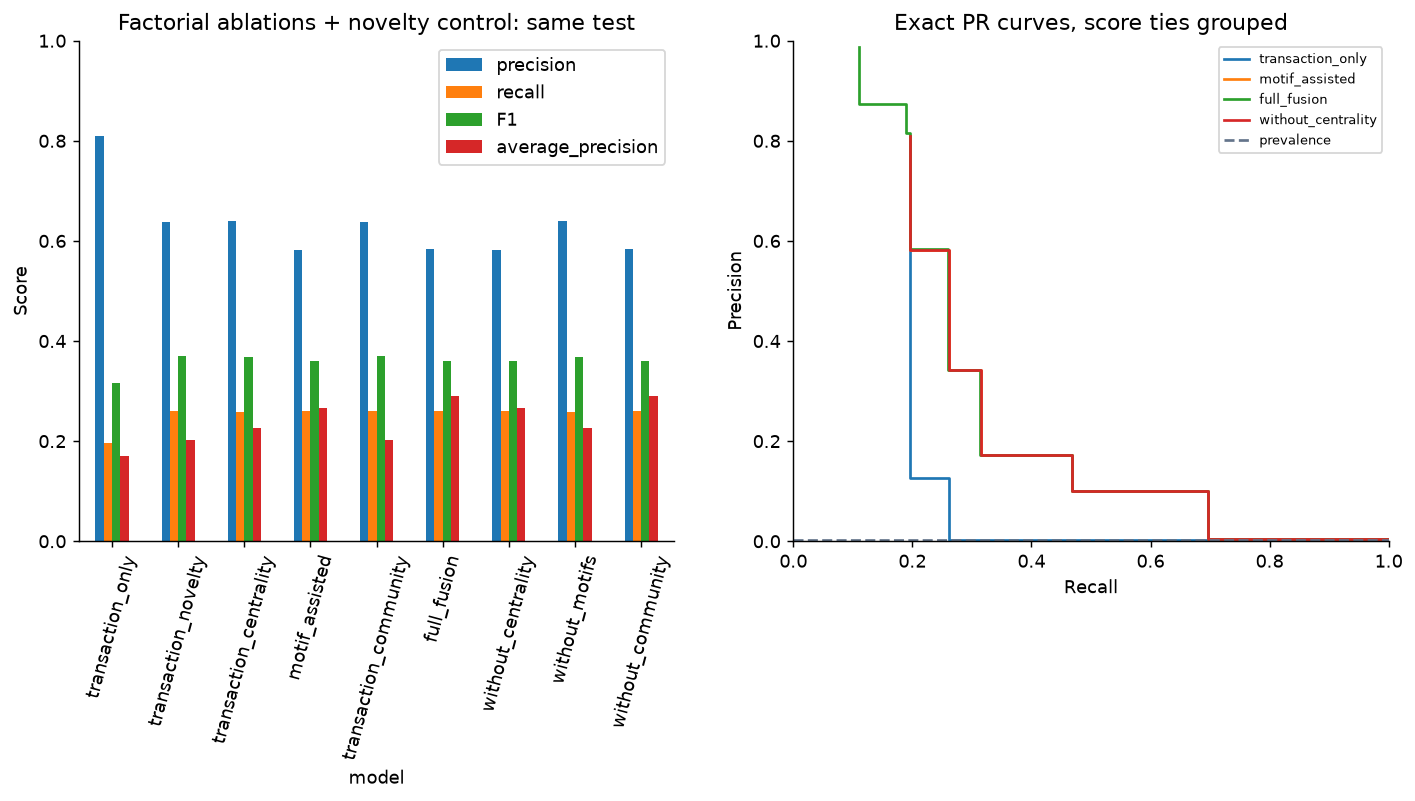

In [13]:
# Cell C12: Official Full-Run Test Results (6,362,620 Transactions)
import hashlib
from IPython.display import Image, display

# 1. Kiểm tra tính toàn vẹn (SHA-256) của file checkpoint theo MANIFEST.json
manifest_path = repo_root / "results" / "presentation_checkpoint" / "MANIFEST.json"
assert manifest_path.exists(), "Thiếu file MANIFEST.json!"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = json.load(f)

official_metrics_rel = "paysim/tables/test_metrics.csv"
official_metrics_path = repo_root / "results" / "presentation_checkpoint" / official_metrics_rel

verification = verify_checkpoint(official_metrics_rel)
print("[CHECKPOINT VERIFIED]", json.dumps(verification, indent=2))

# 2. Đọc bảng kết quả nghiệm thu full run
full_metrics = pd.read_csv(official_metrics_path)
print("\n[BẢNG KẾT QUẢ NGHIỆM THU CHÍNH THỨC FULL RUN (TEST = 1,248,736 GIAO DỊCH, 4,250 FRAUD)]:")
summary_table = full_metrics[["model", "threshold", "alerts", "TP", "FP", "precision", "recall", "F1", "average_precision", "selected_on_validation"]].copy()

for col in ["precision", "recall", "F1", "average_precision"]:
    summary_table[col] = summary_table[col].map(lambda x: f"{x*100:.2f}%")

print(summary_table.to_string(index=False))

# 3. Kiểm tra tính toàn vẹn số liệu bằng assert nghiêm ngặt
tx_base = full_metrics[full_metrics.model == "transaction_only"].iloc[0]
winner = full_metrics[full_metrics.model == "without_centrality"].iloc[0]

assert abs(tx_base.F1 - 0.31654676) < 1e-4, "Sai lệch số liệu baseline F1"
assert abs(tx_base.average_precision - 0.16999535) < 1e-4, "Sai lệch số liệu baseline AP"
assert int(tx_base.TP) == 836, "Sai lệch baseline TP"

assert abs(winner.F1 - 0.36018187) < 1e-4, "Sai lệch số liệu winner F1"
assert abs(winner.average_precision - 0.26580909) < 1e-4, "Sai lệch số liệu winner AP"
assert int(winner.TP) == 1109, "Sai lệch winner TP"
assert winner.threshold == 0.7, "Sai lệch ngưỡng winner"

# 4. Tính toán delta tự động từ dữ liệu (không gõ tay)
delta_f1 = (winner.F1 - tx_base.F1) * 100
delta_ap = (winner.average_precision - tx_base.average_precision) * 100
delta_tp = int(winner.TP) - int(tx_base.TP)
pct_tp = (delta_tp / int(tx_base.TP)) * 100
alert_increase = int(winner.alerts) - int(tx_base.alerts)
prec_drop = (tx_base.precision - winner.precision) * 100

print(f"""
\n[ĐỐI SÁNH HIỆU NĂNG TÍNH TOÁN ĐỘNG TỪ CSV]:
  • Baseline (transaction_only):   F1 = {tx_base.F1*100:.2f}%, AP = {tx_base.average_precision*100:.2f}%, TP = {int(tx_base.TP):,}, Precision = {tx_base.precision*100:.2f}%
  • Winner (without_centrality):   F1 = {winner.F1*100:.2f}%, AP = {winner.average_precision*100:.2f}%, TP = {int(winner.TP):,}, Precision = {winner.precision*100:.2f}%
  • ĐỘ CẢI THIỆN:                  F1 tăng {delta_f1:.2f} điểm %, AP tăng {delta_ap:.2f} điểm %, TP tăng +{delta_tp:,} ca (+{pct_tp:.1f}%)
  • ĐÁNH ĐỔI THỰC TẾ:              Precision giảm {prec_drop:.2f} điểm % (từ {tx_base.precision*100:.2f}% xuống {winner.precision*100:.2f}%) do số lượng cảnh báo tăng thêm +{alert_increase:,} cảnh báo.""")

# Hiển thị đường cong Precision-Recall của 9 họ từ full run
pr_curve_img = checkpoint_dir / "figures" / "ablation_and_pr.png"
if pr_curve_img.exists():
    print("\n[BIỂU ĐỒ ABLATION VÀ ĐƯỜNG CONG PRECISION-RECALL TOÀN DIỆN]:")
    display(Image(filename=str(pr_curve_img), width=750))


#### 5.2 Ngân Sách Điều Tra (Review Budgets) & Ca Bằng Chứng Thực Tế (Case Evidence)
*Lời trình bày:* Trong nghiệp vụ AML/Fraud thực tế, ngân hàng bị giới hạn về nhân sự điều tra. Đánh giá ở các mức ngân sách 0.1%, 0.5%, 1.0% giao dịch có rủi ro cao nhất. Kèm theo một ca True Positive cụ thể được trích xuất từ dữ liệu full run.


[HIỆU QUẢ THEO NGÂN SÁCH ĐIỀU TRA (TOP 0.1%, 0.5%, 1.0% GIAO DỊCH)]:
             model review_fraction     K  TP_at_K precision_at_K recall_at_K
  transaction_only            0.1%  1249      844         67.57%      19.86%
  transaction_only            0.5%  6244     1014         16.24%      23.86%
  transaction_only            1.0% 12488     1120          8.97%      26.35%
without_centrality            0.1%  1249      900         72.06%      21.18%
without_centrality            0.5%  6244     1523         24.39%      35.84%
without_centrality            1.0% 12488     2044         16.37%      48.09%


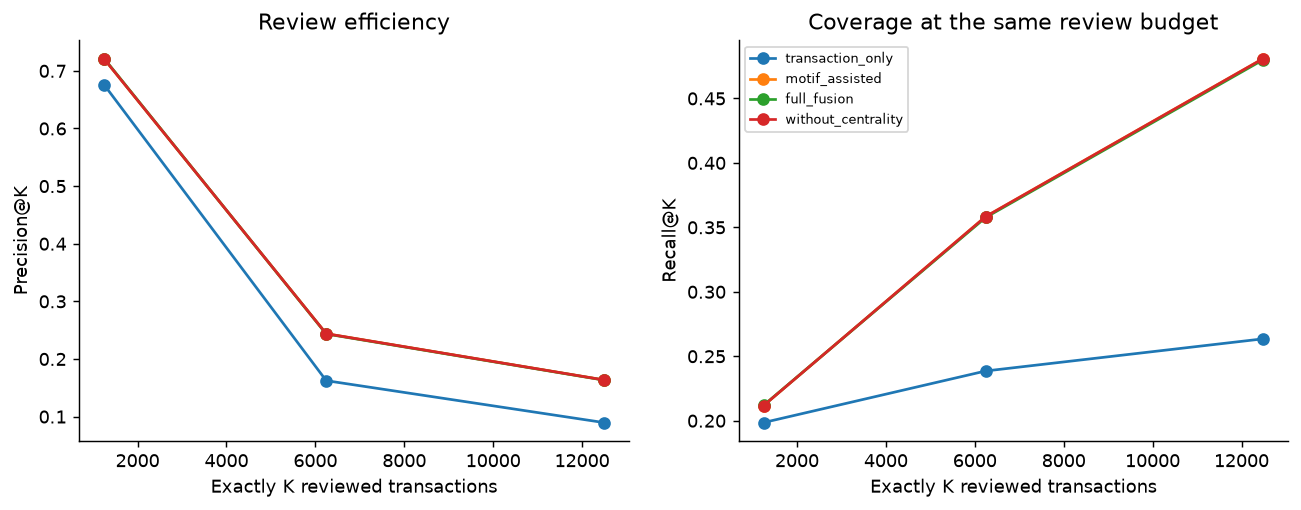


[CA BẰNG CHỨNG ĐIỂN HÌNH ĐÃ KIỂM CHỨNG TỪ CHECKPOINT]:
   event_id        src         dst  step     type    amount payment_currency  isFraud      example_model                               evidence_kind
60129557010 C676427076 C1523524779   470 CASH_OUT 864994.24      PaySim unit      1.0 without_centrality transaction only; no eligible motif witness

Chi tiết giao dịch phát hiện thành công:
  • Mã giao dịch (event_id): 60129557010
  • Tài khoản nguồn: C676427076 -> Đích: C1523524779
  • Số tiền: 864,994.24 | Loại: CASH_OUT
  • Điểm rủi ro (risk_score): 0.9389 (Ngưỡng cảnh báo: 0.70)
  • Nhãn thực tế (isFraud): 1.0 (TRUE POSITIVE)
  • Ghi chú trung thực: Không có cycle witness; điểm rủi ro từ without_centrality, không quy kết đóng góp cho riêng một feature.


In [14]:
# Cell C13: Review Budgets at Top K% & Selected Case Evidence
# 1. Bảng Review Budgets
budgets_path = checkpoint_dir / "tables" / "review_budgets.csv"
budgets_df = pd.read_csv(budgets_path)

view_budgets = budgets_df[budgets_df.model.isin(["transaction_only", "without_centrality"])].copy()
view_budgets["review_fraction"] = view_budgets["review_fraction"].map(lambda x: f"{x*100:.1f}%")
view_budgets["precision_at_K"] = view_budgets["precision_at_K"].map(lambda x: f"{x*100:.2f}%")
view_budgets["recall_at_K"] = view_budgets["recall_at_K"].map(lambda x: f"{x*100:.2f}%")

print("[HIỆU QUẢ THEO NGÂN SÁCH ĐIỀU TRA (TOP 0.1%, 0.5%, 1.0% GIAO DỊCH)]:")
print(view_budgets[["model", "review_fraction", "K", "TP_at_K", "precision_at_K", "recall_at_K"]].to_string(index=False))

budgets_img = checkpoint_dir / "figures" / "review_budgets.png"
if budgets_img.exists():
    display(Image(filename=str(budgets_img), width=650))

# 2. Ca Bằng Chứng True Positive Cụ Thể
case_path = checkpoint_dir / "tables" / "selected_case_evidence.csv"
case_df = pd.read_csv(case_path)
print("\n[CA BẰNG CHỨNG ĐIỂN HÌNH ĐÃ KIỂM CHỨNG TỪ CHECKPOINT]:")
print(case_df.to_string(index=False))

ex_json_path = checkpoint_dir / "examples" / "examples_without_centrality_TP.json"
if ex_json_path.exists():
    with open(ex_json_path, "r", encoding="utf-8") as f:
        cases = json.load(f)
    assert cases and all(int(case["isFraud"]) == 1 and bool(case["alert"]) for case in cases)
    print(f"""
Chi tiết giao dịch phát hiện thành công:
  • Mã giao dịch (event_id): {cases[0].get('event_id')}
  • Tài khoản nguồn: {cases[0].get('src')} -> Đích: {cases[0].get('dst')}
  • Số tiền: {cases[0].get('amount'):,.2f} | Loại: {cases[0].get('type')}
  • Điểm rủi ro (risk_score): {cases[0].get('risk_score'):.4f} (Ngưỡng cảnh báo: 0.70)
  • Nhãn thực tế (isFraud): {cases[0].get('isFraud')} (TRUE POSITIVE)
  • Ghi chú trung thực: Không có cycle witness; điểm rủi ro từ without_centrality, không quy kết đóng góp cho riêng một feature.""")


---
### CHẶNG 6: DỌN DẸP HẠ TẦNG VÀ GIẢI PHÓNG TÀI NGUYÊN (TEARDOWN)
*Lời trình bày:* Dừng SparkSession giải phóng bộ nhớ heap JVM và tự động dọn dẹp thư mục tạm scratch, bảo đảm không để lại file rác trong workspace.


In [15]:
# Cell C14: Measurements, Teardown & Cleanup
resource_measurements = hardware_guard._GUARD.snapshot()
resource_measurements["sample_transactions"] = tx_total
resource_measurements["sample_transactions_per_job_second"] = round(tx_total / resource_measurements["job_wall_seconds"], 2)
print("[MEASURED RESOURCE USAGE]", json.dumps(resource_measurements, indent=2))
spark.catalog.clearCache()
spark.stop()
temp_scratch_obj.cleanup()
print("[TEARDOWN COMPLETED] Đã dừng Spark và xóa scratch của lần demo này.")
print("Kernel phải được đóng sau Run All để giải phóng JVM/khóa workload.")
print("[SCOPE] Live SAMPLE; bảng/hình FULL được đọc từ checkpoint đã kiểm tra SHA-256.")


[MEASURED RESOURCE USAGE] {
  "cpu_hard_cap_percent": 100,
  "max_logical_cpus": 20,
  "spark_task_slots": 20,
  "job_cpu_seconds": 1901.766,
  "job_wall_seconds": 435.563,
  "average_job_cpu_percent": 21.83,
  "maximum_job_cpu_percent": 46.45,
  "job_commit_cap_gib": 8.0,
  "peak_job_commit_gib": 5.26,
  "minimum_available_ram_gib": 15.59,
  "maximum_host_cpu_percent": 78.9,
  "thermal_sensor": "CPU temperature unavailable; not a thermal/power hardware guarantee",
  "sample_transactions": 100729,
  "sample_transactions_per_job_second": 231.26
}


[TEARDOWN COMPLETED] Đã dừng Spark và xóa scratch của lần demo này.
Kernel phải được đóng sau Run All để giải phóng JVM/khóa workload.
[SCOPE] Live SAMPLE; bảng/hình FULL được đọc từ checkpoint đã kiểm tra SHA-256.


---
### TỔNG KẾT VÀ BÀI HỌC KINH NGHIỆM TRUNG THỰC (PRESENTATION TAKEAWAYS)

1. **Hiệu năng thực tế từ mô hình kết hợp:** Trên tập test 1.25M giao dịch PaySim, mô hình kết hợp `without_centrality` (T + Motif + Community) cải thiện đáng kể so với baseline: F1 tăng từ **31.65% lên 36.02%**, Average Precision tăng từ **17.00% lên 26.58%**, phát hiện thêm **+273 ca gian lận (+32.6%)**.
2. **Chi tiết đóng góp của từng nhóm đặc trưng:** Phân tích bóc tách (ablation) cho thấy `without_centrality` và `motif_assisted` đạt kết quả TP, FP và AP giống hệt nhau; nhóm Community không mang lại thêm phân biệt đo lường được trên tập test này.
3. **Đánh đổi nghiệp vụ (Operational Trade-off):** Tăng recall đi kèm cái giá là precision giảm từ **81.01% xuống 58.12%** do số lượng cảnh báo tăng thêm 876 giao dịch (tăng 84.9%).
4. **Minh bạch về kết quả âm tính:** PaySim hoàn toàn không có chu trình 3-cycle khép kín; các cấu trúc relay cũng không bao phủ ca fraud nào. Cây full được chọn chỉ dùng `receiver_in_168h`, amount và type (importance khác 0); chưa quy đóng góp cho mọi đặc trưng motif.
5. **Kỹ thuật Big Data nghiêm ngặt:** Đảm bảo tính nhân quả bằng strict-past và temporal snapshots; bảo vệ hệ thống bằng hardware guard; cắt lineage bằng Parquet staging có giới hạn kích thước partition.
